<a href="https://colab.research.google.com/github/vigneshkv200/Salary-Prediction/blob/main/Texas_Salary_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Analysis

In [ ]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt

#### Readng salary.csv as rawdata

In [ ]:
rawdata=pd.read_csv("salary.csv")

   AGENCY                                        AGENCY NAME  \
0     241  COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...   
1     212  OFFICE OF COURT ADMINISTRATION                ...   
2     241  COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...   
3     212  OFFICE OF COURT ADMINISTRATION                ...   
4     696  TEXAS DEPARTMENT OF CRIMINAL JUSTICE          ...   

                        LAST NAME                      FIRST NAME MI  \
0  RUCKER                          MORTON                          V   
1  RUCKER                          MORTON                          V   
2  SPECIA JR                       JOHN                            J   
3  SPECIA JR                       JOHN                            J   
4  ONTIVEROS                       ESTHER                              

  CLASS CODE                                        CLASS TITLE  \
0   JD25      JUDGE, RETIRED                                ...   
1   3524      GENERAL COUNSEL IV                

In [ ]:
rawdata

,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,...,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",RUCKER,MORTON,V,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,127717,True,NaN,NaN,131407.08,NaN
1,212,OFFICE OF COURT ADMINISTRATION ...,RUCKER,MORTON,V,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04454,4.0,1404.77,16857.24,127717,True,NaN,NaN,NaN,True
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",SPECIA JR,JOHN,J,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,59115,True,NaN,NaN,131407.08,NaN
3,212,OFFICE OF COURT ADMINISTRATION ...,SPECIA JR,JOHN,J,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04453,4.0,1404.77,16857.24,59115,True,NaN,NaN,NaN,True
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,ONTIVEROS,ESTHER,,4504,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3284.27,39411.24,165030,True,1.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149476,809,STATE PRESERVATION BOARD ...,WESSELS,JOHN,P,6232,SECURITY OFFICER III ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,2899.00,34788.00,770781,NaN,NaN,NaN,NaN,NaN
149477,809,STATE PRESERVATION BOARD ...,WINDHAM,EVAN,A,0302,WEB ADMINISTRATOR III ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,5500.00,66000.00,847431,NaN,NaN,NaN,NaN,NaN
149478,809,STATE PRESERVATION BOARD ...,WRIGHT,DERRICK,C,0130,CUSTOMER SERVICE REP I ...,WHITE,MALE,CRP - CLASSIFIED REGULAR PART-TIME,...,12.93000,20.0,1120.60,13447.20,34266,NaN,NaN,NaN,NaN,NaN
149479,809,STATE PRESERVATION BOARD ...,YOUNG,DOUGLAS,R,1572,PROGRAM SPECIALIST III ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,5744.16,68929.92,123490,NaN,NaN,NaN,NaN,NaN


In [ ]:
rawdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149481 entries, 0 to 149480
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   AGENCY                   149481 non-null  int64  
 1   AGENCY NAME              149481 non-null  object 
 2   LAST NAME                149481 non-null  object 
 3   FIRST NAME               149481 non-null  object 
 4   MI                       149481 non-null  object 
 5   CLASS CODE               149481 non-null  object 
 6   CLASS TITLE              149481 non-null  object 
 7   ETHNICITY                149481 non-null  object 
 8   GENDER                   149481 non-null  object 
 9   STATUS                   149481 non-null  object 
 10  EMPLOY DATE              149481 non-null  object 
 11  HRLY RATE                149481 non-null  float64
 12  HRS PER WK               149481 non-null  float64
 13  MONTHLY                  149481 non-null  float64
 14  ANNU

#### Columns dtypes

In [ ]:
rawdata.describe()

,AGENCY,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,multiple_full_time_jobs,summed_annual_salary
count,149481.000000,149481.000000,149481.000000,149481.000000,149481.000000,1.494810e+05,14.0,16.000000
mean,545.736288,0.346488,39.714918,4226.184248,50714.210973,5.651930e+05,1.0,74303.955000
std,139.057691,4.211485,2.323855,2093.111691,25117.340292,4.786212e+05,0.0,51925.944282
min,101.000000,0.000000,1.000000,50.000000,600.000000,1.000000e+00,1.0,18000.000000
25%,529.000000,0.000000,40.000000,3019.840000,36238.080000,1.133340e+05,1.0,32962.500000
50%,530.000000,0.000000,40.000000,3720.170000,44642.040000,3.463730e+05,1.0,48063.300000
75%,696.000000,0.000000,40.000000,4865.810000,58389.720000,1.100500e+06,1.0,123751.770000
max,930.000000,117.788480,70.000000,46125.000000,553500.000000,1.271604e+06,1.0,171383.400000


#### As we can see all the columns most of them are Case sensetive so it needs to be renamed


In [ ]:
rawdata.columns = rawdata.columns.str.lower()  #converting the column names to lower case
rawdata.columns = rawdata.columns.str.replace(' ', '_', regex=False)  # replacing " " with "_"

#### we can see that many of the values in the columns are left blank soo we need to replace it with NaN

In [ ]:
# Replace empty strings, spaces, and 'nan' strings with real NaN
rawdata = rawdata.replace( [""," ","NaN","nan","NULL","null"], np.nan)  # empty or spaces
# rawdata = rawdata.replace('nan', np.nan)                 # string 'nan'


In [ ]:
# print(df)
print("\nNull counts:\n", rawdata.isnull().sum())


Null counts:
 agency                          0
agency_name                     0
last_name                       0
first_name                      0
mi                          38408
class_code                      0
class_title                     0
ethnicity                       0
gender                          0
status                          0
employ_date                     0
hrly_rate                       0
hrs_per_wk                      0
monthly                         0
annual                          0
state_number                    0
duplicated                 149338
multiple_full_time_jobs    149467
combined_multiple_jobs     149384
summed_annual_salary       149465
hide_from_search           149465
dtype: int64


In [ ]:
rawdata.head(10)

,agency,agency_name,last_name,first_name,mi,class_code,class_title,ethnicity,gender,status,...,hrly_rate,hrs_per_wk,monthly,annual,state_number,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",RUCKER,MORTON,V,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,127717,True,NaN,NaN,131407.08,NaN
1,212,OFFICE OF COURT ADMINISTRATION ...,RUCKER,MORTON,V,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04454,4.0,1404.77,16857.24,127717,True,NaN,NaN,NaN,True
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",SPECIA JR,JOHN,J,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,59115,True,NaN,NaN,131407.08,NaN
3,212,OFFICE OF COURT ADMINISTRATION ...,SPECIA JR,JOHN,J,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04453,4.0,1404.77,16857.24,59115,True,NaN,NaN,NaN,True
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,ONTIVEROS,ESTHER,NaN,4504,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3284.27,39411.24,165030,True,1.0,NaN,NaN,NaN
5,302,OFFICE OF THE ATTORNEY GENERAL ...,ROGERS,SHAUNA,NaN,1623,DIRECTOR IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,12899.00,154788.00,1177785,True,1.0,NaN,NaN,NaN
6,601,TEXAS DEPARTMENT OF TRANSPORTATION ...,RICHTER,WILLIAM,J,1984,CONTRACT SPEC IV ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,5835.50,70026.00,1085586,True,1.0,NaN,NaN,NaN
7,510,TEXAS BEHAVIORAL HEALTH EXECUTIVE COUNCIL ...,SPINKS,DARREL,D,1623,DIRECTOR IV ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,10000.00,120000.00,147334,True,NaN,NaN,171383.40,NaN
8,520,BOARD OF EXAMINERS OF PSYCHOLOGISTS ...,SPINKS,DARREL,D,E178,"EXEC DIR, BD OF EXAMS OF PSYCHOLOGISTS ...",WHITE,MALE,ERP - EXEMPT REGULAR PART-TIME,...,49.40717,20.0,4281.95,51383.40,147334,True,NaN,NaN,NaN,True
9,537,DEPARTMENT OF STATE HEALTH SERVICES ...,ADAMS III,LEE,A,1323,INSPECTOR III ...,BLACK,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3447.25,41367.00,129635,True,1.0,NaN,NaN,NaN


In [ ]:
rawdata.isnull().sum()

agency                          0
agency_name                     0
last_name                       0
first_name                      0
mi                          38408
class_code                      0
class_title                     0
ethnicity                       0
gender                          0
status                          0
employ_date                     0
hrly_rate                       0
hrs_per_wk                      0
monthly                         0
annual                          0
state_number                    0
duplicated                 149338
multiple_full_time_jobs    149467
combined_multiple_jobs     149384
summed_annual_salary       149465
hide_from_search           149465
dtype: int64

In [ ]:
rawdata.head(10)

,agency,agency_name,last_name,first_name,mi,class_code,class_title,ethnicity,gender,status,...,hrly_rate,hrs_per_wk,monthly,annual,state_number,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",RUCKER,MORTON,V,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,127717,True,NaN,NaN,131407.08,NaN
1,212,OFFICE OF COURT ADMINISTRATION ...,RUCKER,MORTON,V,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04454,4.0,1404.77,16857.24,127717,True,NaN,NaN,NaN,True
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",SPECIA JR,JOHN,J,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,59115,True,NaN,NaN,131407.08,NaN
3,212,OFFICE OF COURT ADMINISTRATION ...,SPECIA JR,JOHN,J,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04453,4.0,1404.77,16857.24,59115,True,NaN,NaN,NaN,True
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,ONTIVEROS,ESTHER,NaN,4504,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3284.27,39411.24,165030,True,1.0,NaN,NaN,NaN
5,302,OFFICE OF THE ATTORNEY GENERAL ...,ROGERS,SHAUNA,NaN,1623,DIRECTOR IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,12899.00,154788.00,1177785,True,1.0,NaN,NaN,NaN
6,601,TEXAS DEPARTMENT OF TRANSPORTATION ...,RICHTER,WILLIAM,J,1984,CONTRACT SPEC IV ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,5835.50,70026.00,1085586,True,1.0,NaN,NaN,NaN
7,510,TEXAS BEHAVIORAL HEALTH EXECUTIVE COUNCIL ...,SPINKS,DARREL,D,1623,DIRECTOR IV ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,10000.00,120000.00,147334,True,NaN,NaN,171383.40,NaN
8,520,BOARD OF EXAMINERS OF PSYCHOLOGISTS ...,SPINKS,DARREL,D,E178,"EXEC DIR, BD OF EXAMS OF PSYCHOLOGISTS ...",WHITE,MALE,ERP - EXEMPT REGULAR PART-TIME,...,49.40717,20.0,4281.95,51383.40,147334,True,NaN,NaN,NaN,True
9,537,DEPARTMENT OF STATE HEALTH SERVICES ...,ADAMS III,LEE,A,1323,INSPECTOR III ...,BLACK,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3447.25,41367.00,129635,True,1.0,NaN,NaN,NaN


#### Remove the rows where duplicated =True

In [ ]:
rawdata=rawdata[rawdata["duplicated"] !=True]

In [ ]:
rawdata

,agency,agency_name,last_name,first_name,mi,class_code,class_title,ethnicity,gender,status,...,hrly_rate,hrs_per_wk,monthly,annual,state_number,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
143,103,TEXAS LEGISLATIVE COUNCIL ...,ABDULHUSSAIN,OSAMA,J,4423,PROG IV ...,WHITE,MALE,URF - UNCLASSIFIED REGULAR FULL-TIME,...,0.00,40.0,6792.27,81507.24,338060,NaN,NaN,NaN,NaN,NaN
144,103,TEXAS LEGISLATIVE COUNCIL ...,AKBAR,SARAH,NaN,2135,LEG COUN I ...,ASIAN,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,...,0.00,40.0,5471.60,65659.20,1138232,NaN,NaN,NaN,NaN,NaN
145,103,TEXAS LEGISLATIVE COUNCIL ...,ALBERTSON,GLENDA,L,4315,MEDIA & EDUCATION TEAM LEAD ...,WHITE,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,...,0.00,40.0,5816.67,69800.04,42523,NaN,NaN,NaN,NaN,NaN
146,103,TEXAS LEGISLATIVE COUNCIL ...,ALEXANDER,ANGELA,J,2105,SPECIAL COUNSEL ...,WHITE,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,...,0.00,40.0,10395.26,124743.12,118947,NaN,NaN,NaN,NaN,NaN
147,103,TEXAS LEGISLATIVE COUNCIL ...,ALIKUTTY SAINABA,RINCY,NaN,1154,RECEPTIONIST ...,ASIAN,FEMALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,0.00,25.0,1770.83,21249.96,1142514,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149476,809,STATE PRESERVATION BOARD ...,WESSELS,JOHN,P,6232,SECURITY OFFICER III ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00,40.0,2899.00,34788.00,770781,NaN,NaN,NaN,NaN,NaN
149477,809,STATE PRESERVATION BOARD ...,WINDHAM,EVAN,A,0302,WEB ADMINISTRATOR III ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00,40.0,5500.00,66000.00,847431,NaN,NaN,NaN,NaN,NaN
149478,809,STATE PRESERVATION BOARD ...,WRIGHT,DERRICK,C,0130,CUSTOMER SERVICE REP I ...,WHITE,MALE,CRP - CLASSIFIED REGULAR PART-TIME,...,12.93,20.0,1120.60,13447.20,34266,NaN,NaN,NaN,NaN,NaN
149479,809,STATE PRESERVATION BOARD ...,YOUNG,DOUGLAS,R,1572,PROGRAM SPECIALIST III ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00,40.0,5744.16,68929.92,123490,NaN,NaN,NaN,NaN,NaN


#### We can drop columns "last_name","first_name","mi" as its unique for all and it cannot be used for finding patterns among them  

In [ ]:
rawdata.drop(["last_name","first_name","mi"],axis=1,inplace=True)


#### counts of unique

In [ ]:
rawdata["agency"].value_counts(dropna=False)

agency
529    36664
696    35925
601    13098
530    12585
405    10097
       ...  
907        8
364        7
481        5
464        4
213        4
Name: count, Length: 112, dtype: int64

In [ ]:
rawdata["gender"].value_counts(dropna=False)


gender
FEMALE             85263
MALE               64075
Name: count, dtype: int64

In [ ]:
rawdata["class_title"].value_counts(dropna=False)

class_title
CORREC  OFFICER IV                                    9266
CORREC  OFFICER V                                     7895
CORREC OFFCR III                                      4718
TEXAS WORKS ADVISOR II                                3646
DIRECT SUPPORT PROFESSIONAL I                         3307
                                                      ... 
PSF CHIEF INVESTMENT OFFICER                             1
MED FEE DISPUTE OFFICER I                                1
COMMISSIONER, TEXAS EDUCATION                            1
RESEARCH DAT ANALYST                                     1
PROOFREADER II                                           1
Name: count, Length: 1421, dtype: int64

In [ ]:
rawdata["class_code"].value_counts(dropna=False)

class_code
4504        9266
4505        7895
4503        4718
5622        3646
5121        3307
            ... 
3230           1
9305           1
E021           1
5303           1
E096           1
Name: count, Length: 1480, dtype: int64

In [ ]:
rawdata["agency_name"].value_counts(dropna=False)

agency_name
HEALTH AND HUMAN SERVICES COMMISSION                  36664
TEXAS DEPARTMENT OF CRIMINAL JUSTICE                  35925
TEXAS DEPARTMENT OF TRANSPORTATION                    13098
DEPARTMENT OF FAMILY AND PROTECTIVE SERVICES          12585
DEPARTMENT OF PUBLIC SAFETY                           10097
                                                      ...  
COMPTROLLER OF PUBLIC ACCOUNTS, STATE ENERGY CONSE        8
HEALTH PROFESSIONS COUNCIL                                7
BOARD OF PROFESSIONAL GEOSCIENTISTS                       5
BOARD OF PROFESSIONAL LAND SURVEYING                      4
OFFICE OF STATE PROSECUTING ATTORNEY                      4
Name: count, Length: 112, dtype: int64

In [ ]:
rawdata["state_number"].value_counts(dropna=False)

state_number
338060    1
840072    1
131133    1
139653    1
157228    1
         ..
981625    1
104071    1
95533     1
10532     1
103583    1
Name: count, Length: 149338, dtype: int64

In [ ]:
rawdata["status"].value_counts(dropna=False)

status
CRF - CLASSIFIED REGULAR FULL-TIME          142449
URF - UNCLASSIFIED REGULAR FULL-TIME          2306
CRP - CLASSIFIED REGULAR PART-TIME            1517
CTF - CLASSIFIED TEMPORARY FULL-TIME          1096
URP - UNCLASSIFIED REGULAR PART-TIME           935
ERF - EXEMPT REGULAR FULL-TIME                 923
CTP - CLASSIFIED TEMPORARY PART-TIME            79
UTP - UNCLASSIFIED TEMPORARY PART-TIME          21
UTF - UNCLASSIFIED TEMPORARY FULL-TIME          12
Name: count, dtype: int64

In [ ]:
rawdata["duplicated"].value_counts(dropna=False) ##As around 143 data are present lets keep it for further investigation


duplicated
NaN    149338
Name: count, dtype: int64

In [ ]:
rawdata["ethnicity"].value_counts(dropna=False) # Almost all records are present



ethnicity
WHITE              67046
HISPANIC           40555
BLACK              35845
ASIAN               4265
OTHER                916
AM INDIAN            711
Name: count, dtype: int64

In [ ]:
rawdata["multiple_full_time_jobs"].value_counts(dropna=False) # This Column can be Dropped as majour data is missing


multiple_full_time_jobs
NaN    149338
Name: count, dtype: int64

In [ ]:
rawdata["combined_multiple_jobs"].value_counts(dropna=False) # This Column can be Dropped as majour data is missing


combined_multiple_jobs
NaN    149338
Name: count, dtype: int64

In [ ]:
rawdata["summed_annual_salary"].value_counts(dropna=False) # This Column can be Dropped as majour data is missing


summed_annual_salary
NaN    149338
Name: count, dtype: int64

In [ ]:
rawdata["hide_from_search"].value_counts(dropna=False)

hide_from_search
NaN    149338
Name: count, dtype: int64

#### Droping of columns multiple_full_time_jobs","combined_multiple_jobs","summed_annual_salary","hide_from_search" And "duplicated" as duplicated data was handled

In [ ]:
rawdata.drop(["multiple_full_time_jobs","combined_multiple_jobs","summed_annual_salary","hide_from_search","duplicated"],axis=1,inplace=True)


In [ ]:
rawdata.head()

,agency,agency_name,class_code,class_title,ethnicity,gender,status,employ_date,hrly_rate,hrs_per_wk,monthly,annual,state_number,duplicated
143,103,TEXAS LEGISLATIVE COUNCIL ...,4423,PROG IV ...,WHITE,MALE,URF - UNCLASSIFIED REGULAR FULL-TIME,03/18/13,0.0,40.0,6792.27,81507.24,338060,NaN
144,103,TEXAS LEGISLATIVE COUNCIL ...,2135,LEG COUN I ...,ASIAN,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,09/01/18,0.0,40.0,5471.60,65659.20,1138232,NaN
145,103,TEXAS LEGISLATIVE COUNCIL ...,4315,MEDIA & EDUCATION TEAM LEAD ...,WHITE,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,06/01/10,0.0,40.0,5816.67,69800.04,42523,NaN
146,103,TEXAS LEGISLATIVE COUNCIL ...,2105,SPECIAL COUNSEL ...,WHITE,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,03/16/98,0.0,40.0,10395.26,124743.12,118947,NaN
147,103,TEXAS LEGISLATIVE COUNCIL ...,1154,RECEPTIONIST ...,ASIAN,FEMALE,URP - UNCLASSIFIED REGULAR PART-TIME,10/01/18,0.0,25.0,1770.83,21249.96,1142514,NaN


In [ ]:
rawdata.info()

<class 'pandas.core.frame.DataFrame'>
Index: 149338 entries, 143 to 149480
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   agency        149338 non-null  int64  
 1   agency_name   149338 non-null  object 
 2   class_code    149338 non-null  object 
 3   class_title   149338 non-null  object 
 4   ethnicity     149338 non-null  object 
 5   gender        149338 non-null  object 
 6   status        149338 non-null  object 
 7   employ_date   149338 non-null  object 
 8   hrly_rate     149338 non-null  float64
 9   hrs_per_wk    149338 non-null  float64
 10  monthly       149338 non-null  float64
 11  annual        149338 non-null  float64
 12  state_number  149338 non-null  int64  
 13  duplicated    0 non-null       object 
dtypes: float64(4), int64(2), object(8)
memory usage: 17.1+ MB


#### now we have Dropped columns which are not required for further keeping "duplicated " column for future investigation

### outliers detection

In [ ]:
import seaborn as sns


<Axes: xlabel='hrly_rate'>

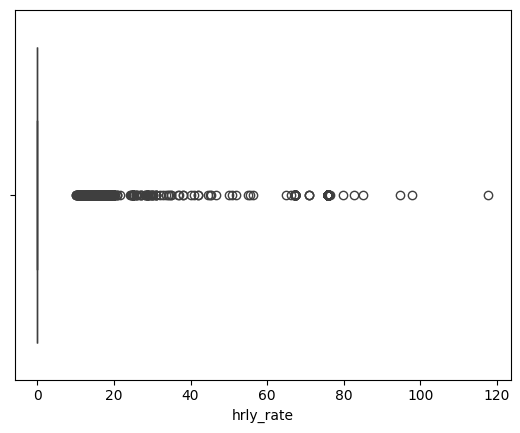

In [ ]:
sns.boxplot(data=rawdata.hrly_rate,orient="h")


<Axes: xlabel='hrs_per_wk'>

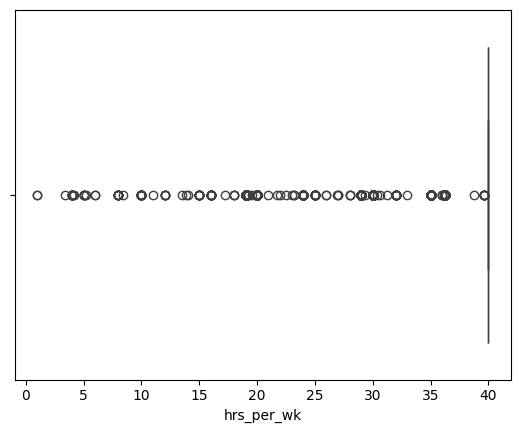

In [ ]:
sns.boxplot(data=rawdata.hrs_per_wk,orient="h")

<Axes: xlabel='monthly'>

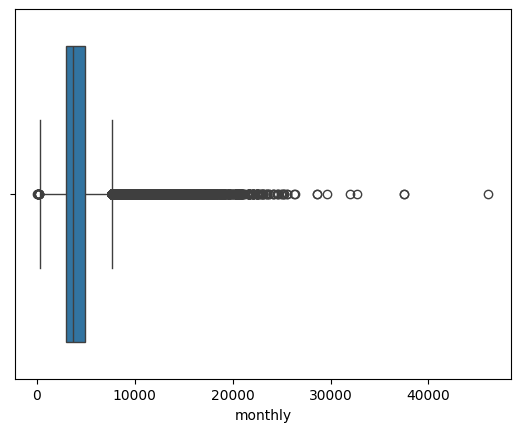

In [ ]:
sns.boxplot(data=rawdata.monthly,orient="h")


<Axes: xlabel='annual'>

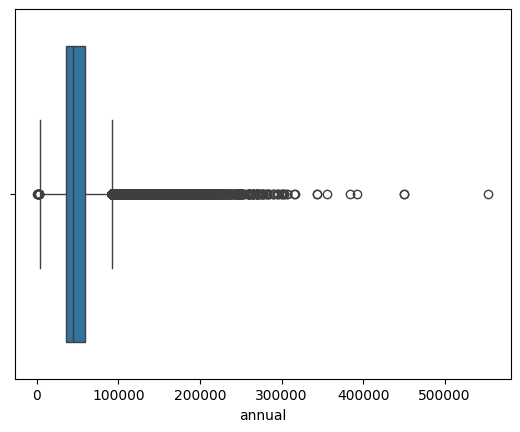

In [ ]:
sns.boxplot(data=rawdata.annual,orient="h")


<Axes: >

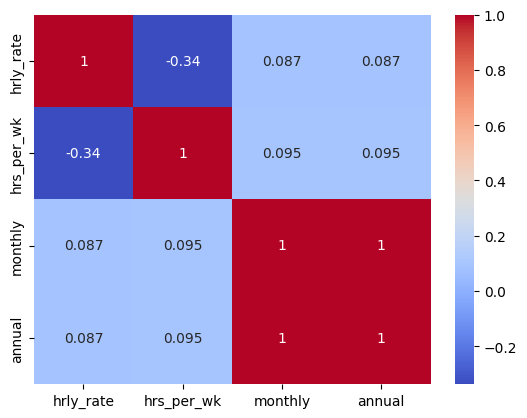

In [ ]:
import seaborn as sns
sns.heatmap(rawdata[["hrly_rate","hrs_per_wk","monthly","annual"]].corr(),annot=True,cmap="coolwarm")


##### we hear can notice Monthly and annual columns are completly corelated this says we can drop any one of them and consider one as target

In [ ]:
rawdata.columns

Index(['agency', 'agency_name', 'class_code', 'class_title', 'ethnicity',
       'gender', 'status', 'employ_date', 'hrly_rate', 'hrs_per_wk', 'monthly',
       'annual', 'state_number', 'duplicated'],
      dtype='object')

lets see which columns are contributing how much for the target column annual

### Task 3:-
##### 1●	Who are the outliers in the salaries?


USING IQR FOR FINDING OUTLIERS

In [ ]:
Q1=rawdata["annual"].quantile(0.25)
Q3=rawdata["annual"].quantile(0.75)

IQR= Q3-Q1

upper_limit=Q3+1.5*IQR

outliers =rawdata[rawdata["annual"] > upper_limit].copy()

#### which class title have highest saleries



In [ ]:
outliers.groupby("class_title")["annual"].agg(["count","mean","max"]).sort_values("max",ascending=False).info()

<class 'pandas.core.frame.DataFrame'>
Index: 362 entries, CHIEF SCIENTIFIC OFFICER                           to INFO TECHNOLOGY SECURITY ANLYS                    
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   count   362 non-null    int64  
 1   mean    362 non-null    float64
 2   max     362 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 11.3+ KB


In [ ]:
outliers.groupby("class_title")["annual"].agg(["count","mean","max"]).sort_values("max",ascending=False).head(20)

,count,mean,max
class_title,,,
CHIEF SCIENTIFIC OFFICER,1,553500.000000,553500.00
DIRECTOR OF INVESTMENTS,1,450000.000000,450000.00
CHIEF INVESTMENT OFFICER,3,300572.000000,450000.00
SENIOR MANAGING DIRECTOR,6,319000.000000,391999.92
PSF CHIEF INVESTMENT OFFICER,1,384375.000000,384375.00
EXECUTIVE DIRECTOR,42,161803.705714,355141.44
EXECUTIVE DIRECTOR FOR ERS,1,316116.960000,316116.96
MANAGING DIRECTOR,2,310999.980000,315000.00
SENIOR DIRECTOR,18,184444.720000,302000.04


In [ ]:
outliers["gender"].value_counts()


gender
MALE               5308
FEMALE             3686
Name: count, dtype: int64

In [ ]:
rawdata["gender"].value_counts()

gender
FEMALE             85263
MALE               64075
Name: count, dtype: int64

#### hear we can notice that among 85328 male 5329 are outliers and among 64153 females 3689 are outliers both are around 4-9% of the data

In [ ]:
outliers["class_title"].value_counts().head(10)

class_title
DIRECTOR II                                           645
DIRECTOR III                                          576
DISTRICT JUDGE, ACTIVE                                472
MGR V                                                 462
DIRECTOR IV                                           368
JUDGE, RETIRED                                        322
DIRECTOR I                                            267
ATTORNEY IV                                           234
SYSTEMS ANALYST VI                                    215
ENGINEER V                                            204
Name: count, dtype: int64

##### TOP 10 job titles in outliers list

In [ ]:
hourly = rawdata[rawdata["hrly_rate"]>0]
hourly["class_title"].value_counts().head(10)

class_title
ENGINEERING AIDE                                      418
JUDGE, RETIRED                                        321
MAINTENANCE SPECIALIST I                              239
CUSTOMER SERVICE REP I                                134
HOURLY/SUBSTITUTES                                     84
SUBSTITUTE WORKERS                                     82
CLERK I                                                73
ADMINISTRATIVE ASST I                                  63
RETIRED COUNTY COURT JUDGE                             61
LICENSE AND PERMIT SPEC II                             38
Name: count, dtype: int64

#### Hear we can notice the top 10 job titles who earn in hrly_rate



In [ ]:
hourly = outliers[outliers["hrly_rate"]>0]
hourly["class_title"].value_counts().head(10)

class_title
JUDGE, RETIRED                                        321
RETIRED COUNTY COURT JUDGE                             61
DISTRICT JUDGE, FORMER                                 14
PHYSICIAN III                                           2
PROJECT MANAGER IV                                      1
PSYCHIATRIST III                                        1
Name: count, dtype: int64

#### 6 job titles among salary outliers have been paid in hrly_rate


In [ ]:
rawdata["ethnicity"].value_counts(dropna=False) # Almost all records are present


ethnicity
WHITE              67046
HISPANIC           40555
BLACK              35845
ASIAN               4265
OTHER                916
AM INDIAN            711
Name: count, dtype: int64

In [ ]:
outliers["ethnicity"].value_counts()

ethnicity
WHITE              6330
HISPANIC           1354
ASIAN               656
BLACK               573
AM INDIAN            48
OTHER                33
Name: count, dtype: int64

In [ ]:
ethnicity_table =pd.DataFrame({
    "Total":rawdata["ethnicity"].value_counts(dropna=False),
    "outliers":outliers["ethnicity"].value_counts()
    })
ethnicity_table["Percentage"]=ethnicity_table["outliers"]/ethnicity_table["Total"] *100

print(ethnicity_table.sort_values("Percentage",ascending=False))

                 Total  outliers  Percentage
ethnicity                                   
ASIAN             4265       656   15.381008
WHITE            67046      6330    9.441279
AM INDIAN          711        48    6.751055
OTHER              916        33    3.602620
HISPANIC         40555      1354    3.338676
BLACK            35845       573    1.598549


#### total and outliers ethnicity THE Asian stands with 15.37%

### Task 3:-
##### 2●	What departments/roles have the biggest wage disparities between managers and employees?


In [ ]:
df_clean =rawdata.copy()
manager_kw = r'MANAGER|DIRECTOR|SUPERVISOR|CHIEF|ADMINISTRATOR|HEAD'
df_clean['is_manager'] = rawdata['class_title'].str.contains(
    manager_kw, case=False, na=False
)
df_clean['annual'] = rawdata['annual']
mgr_gap = df_clean.groupby('is_manager')['annual'].agg(
    ['mean', 'median', 'count']
)

print(mgr_gap)

                    mean    median   count
is_manager                                
False       48648.470401  44642.04  141330
True        86900.560115  77312.46    8008


In [ ]:
df_clean['level'] = rawdata['class_title'].str.extract(
    r'\b(I{1,3}|IV|V)\b\s*$'
)

df_clean['base_title'] = rawdata['class_title'].str.replace(
    r'\s*\b(I{1,3}|IV|V)\b\s*$',
    '',
    regex=True
).str.strip()

In [ ]:
level_pivot = (
    df_clean[df_clean['level'].notna()]
    .groupby(['agency_name', 'base_title', 'level'])['annual']
    .mean()
    .unstack()
)

In [ ]:
print(df_clean.columns)


Index(['agency', 'agency_name', 'class_code', 'class_title', 'ethnicity',
       'gender', 'status', 'employ_date', 'hrly_rate', 'hrs_per_wk', 'monthly',
       'annual', 'state_number', 'duplicated', 'is_manager', 'level',
       'base_title'],
      dtype='object')


In [ ]:
level_pivot = level_pivot.dropna(thresh=2)

In [ ]:
level_pivot['gap'] = (
    level_pivot.max(axis=1) -
    level_pivot.min(axis=1)
)

In [ ]:
biggest_gaps = level_pivot.sort_values(
    'gap',
    ascending=False
).head(15)

print(biggest_gaps)

level                                                                              I  \
agency_name                                        base_title                          
GENERAL LAND OFFICE AND VETERAN'S LAND BOARD       PORTFOLIO MANAGER    94858.320000   
EMPLOYEES RETIREMENT SYSTEM                        PORTFOLIO MANAGER   122187.120000   
HEALTH AND HUMAN SERVICES COMMISSION               PHYSICIAN           165399.960000   
EMPLOYEES RETIREMENT SYSTEM                        GENERAL COUNSEL      99343.320000   
TREASURY SAFEKEEPING TRUST COMPANY                 PORTFOLIO MANAGER             NaN   
TEXAS DEPARTMENT OF INSURANCE                      ACTUARY              57520.008000   
TEXAS WORKFORCE COMMISSION                         GENERAL COUNSEL      68021.424000   
PUBLIC UTILITY COMMISSION OF TEXAS                 GENERAL COUNSEL               NaN   
TEACHER RETIREMENT SYSTEM                          DEPUTY DIRECTOR     209817.840000   
                                

### Task 3:-
##### 3●	Have salaries and total compensations for some roles/ departments/ head-count changed over time?


In [ ]:
rawdata["employ_date"].astype(str).str[-2:].value_counts().sort_index()

employ_date
00     1629
01     1598
02     1681
03     1466
04     3547
05     2660
06     2877
07     3354
08     3906
09     3511
10     2959
11     3452
12     4830
13     5998
14     6322
15     7094
16    11376
17    20435
18    15930
19    21985
20    14533
68        1
69        2
71        1
72        1
73        2
75        1
76        5
77        7
78        5
79       12
80       10
81       29
82       21
83       41
84       53
85       84
86       77
87      138
88      128
89      199
90      216
91      203
92      511
93      523
94      725
95      774
96      918
97      960
98     1209
99     1339
Name: count, dtype: int64

this makes us conform that the data are between years 1968-2020

In [ ]:
rawdata["employ_date"]=pd.to_datetime(rawdata["employ_date"].astype(str),format="%m/%d/%y")



In [ ]:
rawdata["employ_date"]=rawdata["employ_date"].apply(lambda x: x.replace(year =x.year -100) if x.year > 2020 else x)

In [ ]:
print("minimum date:",rawdata["employ_date"].min())
print("maximum date:",rawdata["employ_date"].max())

minimum date: 1968-12-01 00:00:00
maximum date: 2020-06-30 00:00:00


##### Average annual salary by year



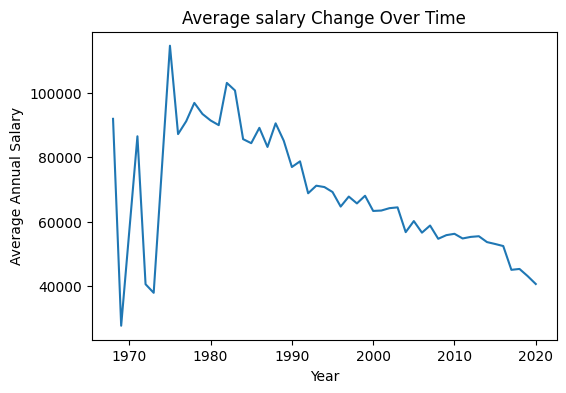

In [ ]:
rawdata["year"]= rawdata["employ_date"].dt.year

salary =rawdata.groupby("year")["annual"].mean()

# print(salary)

salary.plot(figsize=(6,4))

plt.xlabel("Year")
plt.ylabel("Average Annual Salary")
plt.title("Average salary Change Over Time")
plt.show()

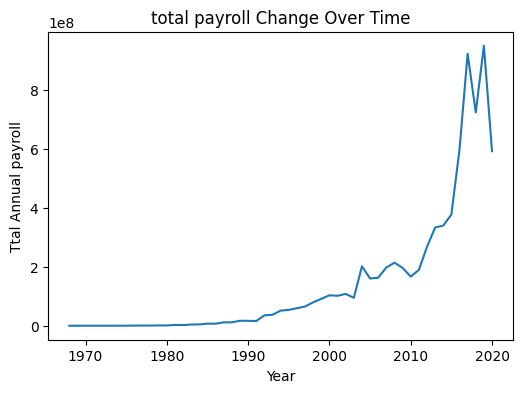

In [ ]:

payroll =rawdata.groupby("year")["annual"].sum()

# print(salary)

payroll.plot(figsize=(6,4))

plt.xlabel("Year")
plt.ylabel("Ttal Annual payroll")
plt.title("total payroll Change Over Time")
plt.show()

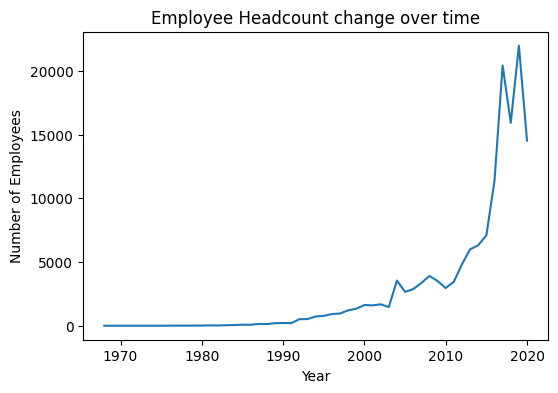

In [ ]:
headcount =rawdata.groupby("year").size()

headcount.plot(figsize=(6,4))


plt.xlabel("Year")
plt.ylabel("Number of Employees")
plt.title("Employee Headcount change over time")
plt.show()

<Axes: >

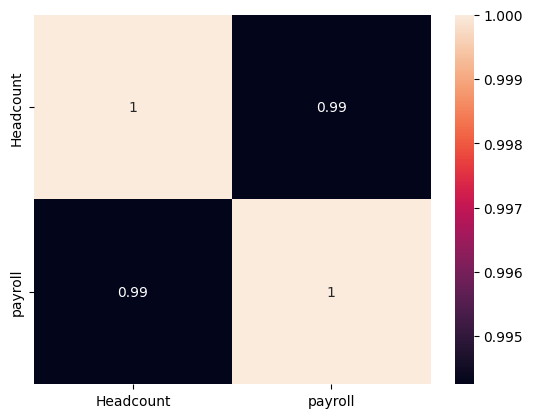

In [ ]:
corr_data=pd.DataFrame({"Headcount":headcount,"payroll":payroll})

sns.heatmap(corr_data.corr(),annot=True)


##### hear we can see the correlation of Headcount and payroll indicating 0.99

In [ ]:
import seaborn as sns
pd.crosstab(rawdata["ethnicity"],rawdata["status"],normalize ="index")*100

status,CRF - CLASSIFIED REGULAR FULL-TIME,CRP - CLASSIFIED REGULAR PART-TIME,CTF - CLASSIFIED TEMPORARY FULL-TIME,CTP - CLASSIFIED TEMPORARY PART-TIME,ERF - EXEMPT REGULAR FULL-TIME,URF - UNCLASSIFIED REGULAR FULL-TIME,URP - UNCLASSIFIED REGULAR PART-TIME,UTF - UNCLASSIFIED TEMPORARY FULL-TIME,UTP - UNCLASSIFIED TEMPORARY PART-TIME
ethnicity,,,,,,,,,
AM INDIAN,96.202532,0.984529,0.703235,0.281294,0.140647,1.265823,0.421941,0.000000,0.000000
ASIAN,95.732708,0.773740,0.937866,0.046893,0.164127,2.016413,0.281360,0.000000,0.046893
BLACK,97.729111,1.135444,0.326405,0.011159,0.133910,0.549589,0.114381,0.000000,0.000000
HISPANIC,96.254469,0.865491,0.978918,0.061645,0.290963,1.235359,0.298360,0.004932,0.009863
OTHER,92.248908,1.965066,2.292576,0.109170,0.000000,2.510917,0.545852,0.109170,0.218341
WHITE,93.622289,1.045551,0.769621,0.067118,1.117143,2.222355,1.123110,0.013424,0.019390


## Prediction

In [ ]:
# Box 1 — Install libraries
!pip install -q mlflow xgboost lightgbm catboost shap



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 100.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 111.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 82.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Box 2 — Imports
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")


In [ ]:
# Box 3 — Load the dataset
# df = pd.read_csv("/content/drive/MyDrive/dm/salary.csv", low_memory=False)
df = pd.read_csv("salary.csv", low_memory=False)
df.head()


,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,...,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",RUCKER,MORTON,V,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,127717,True,NaN,NaN,131407.08,NaN
1,212,OFFICE OF COURT ADMINISTRATION ...,RUCKER,MORTON,V,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04454,4.0,1404.77,16857.24,127717,True,NaN,NaN,NaN,True
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",SPECIA JR,JOHN,J,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,59115,True,NaN,NaN,131407.08,NaN
3,212,OFFICE OF COURT ADMINISTRATION ...,SPECIA JR,JOHN,J,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04453,4.0,1404.77,16857.24,59115,True,NaN,NaN,NaN,True
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,ONTIVEROS,ESTHER,,4504,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3284.27,39411.24,165030,True,1.0,NaN,NaN,NaN


In [ ]:
# Box 4 — Basic dataset information
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())


Shape: (149481, 21)

Columns:
['AGENCY', 'AGENCY NAME', 'LAST NAME', 'FIRST NAME', 'MI', 'CLASS CODE', 'CLASS TITLE', 'ETHNICITY', 'GENDER', 'STATUS', 'EMPLOY DATE', 'HRLY RATE', 'HRS PER WK', 'MONTHLY', 'ANNUAL', 'STATE NUMBER', 'duplicated', 'multiple_full_time_jobs', 'combined_multiple_jobs', 'summed_annual_salary', 'hide_from_search']

Data Types:
AGENCY                       int64
AGENCY NAME                 object
LAST NAME                   object
FIRST NAME                  object
MI                          object
CLASS CODE                  object
CLASS TITLE                 object
ETHNICITY                   object
GENDER                      object
STATUS                      object
EMPLOY DATE                 object
HRLY RATE                  float64
HRS PER WK                 float64
MONTHLY                    float64
ANNUAL                     float64
STATE NUMBER                 int64
duplicated                  object
multiple_full_time_jobs    float64
combined_multipl

In [ ]:
# Box 5 — Basic numerical summary
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AGENCY,149481.0,NaN,NaN,NaN,545.736288,139.057691,101.0,529.0,530.0,696.0,930.0
AGENCY NAME,149481,113,HEALTH AND HUMAN SERVICES COMMISSION ...,36667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LAST NAME,149481,38675,SMITH,1243,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FIRST NAME,149481,23559,MICHAEL,1843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MI,149481,27,,38408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLASS CODE,149481,1481,4504,9267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLASS TITLE,149481,1422,CORREC OFFICER IV ...,9267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ETHNICITY,149481,6,WHITE,67142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GENDER,149481,2,FEMALE,85328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STATUS,149481,11,CRF - CLASSIFIED REGULAR FULL-TIME,142502,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df = df[df["duplicated"] != 1].copy()


In [ ]:
columns_to_drop = [
    "duplicated",
    "multiple_full_time_jobs",
    "combined_multiple_jobs",
    "summed_annual_salary",
    "hide_from_search",
    "STATE NUMBER",
    "CLASS CODE"
]

df = df.drop(columns=columns_to_drop)

In [ ]:
df.columns.tolist()

['AGENCY',
 'AGENCY NAME',
 'LAST NAME',
 'FIRST NAME',
 'MI',
 'CLASS TITLE',
 'ETHNICITY',
 'GENDER',
 'STATUS',
 'EMPLOY DATE',
 'HRLY RATE',
 'HRS PER WK',
 'MONTHLY',
 'ANNUAL']

In [ ]:
df.shape

(149338, 14)

In [ ]:
df.isnull().sum()

,0
AGENCY,0
AGENCY NAME,0
LAST NAME,0
FIRST NAME,0
MI,0
CLASS TITLE,0
ETHNICITY,0
GENDER,0
STATUS,0
EMPLOY DATE,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["CLASS TITLE"].head(30)


,CLASS TITLE
143,PROG IV ...
144,LEG COUN I ...
145,MEDIA & EDUCATION TEAM LEAD ...
146,SPECIAL COUNSEL ...
147,RECEPTIONIST ...
148,PROG III ...
149,SECTION COORDINATOR ...
150,LEG OFFICE CONSULTANT II ...
151,"MGR, COMPUTER SUPPORT CENTER ..."
152,EXEC DIRECTOR ...


In [ ]:
df["CLASS TITLE"].value_counts().head(30)

,count
CLASS TITLE,
CORREC OFFICER IV,9266
CORREC OFFICER V,7895
CORREC OFFCR III,4718
TEXAS WORKS ADVISOR II,3646
DIRECT SUPPORT PROFESSIONAL I,3307
TROOPER,2251
CHILD PROTECTIVE SVCS SPEC IV,1854
CHILD PROTECTIVE SVCS SPEC I,1772
ADMINISTRATIVE ASST III,1769


In [ ]:
# Box 8 — Clean CLASS TITLE
df["CLASS TITLE"] = df["CLASS TITLE"].astype(str).str.strip()


In [ ]:
# Box 9 — Extract level
level_pattern = r"\s+(VIII|VII|VI|V|IV|III|II|I|X|IX)$"

df["level"] = (
    df["CLASS TITLE"]
    .str.extract(level_pattern, expand=False)
    .fillna("NA")
)


In [ ]:
# Box 10 — Create base_title
df["base_title"] = (
    df["CLASS TITLE"]
    .str.replace(level_pattern, "", regex=True)
    .str.strip()
)


In [ ]:
df[["CLASS TITLE", "base_title", "level"]].head(30)

,CLASS TITLE,base_title,level
143,PROG IV,PROG,IV
144,LEG COUN I,LEG COUN,I
145,MEDIA & EDUCATION TEAM LEAD,MEDIA & EDUCATION TEAM LEAD,NA
146,SPECIAL COUNSEL,SPECIAL COUNSEL,NA
147,RECEPTIONIST,RECEPTIONIST,NA
148,PROG III,PROG,III
149,SECTION COORDINATOR,SECTION COORDINATOR,NA
150,LEG OFFICE CONSULTANT II,LEG OFFICE CONSULTANT,II
151,"MGR, COMPUTER SUPPORT CENTER","MGR, COMPUTER SUPPORT CENTER",NA
152,EXEC DIRECTOR,EXEC DIRECTOR,NA


In [ ]:
# Box 11 — Check level distribution
df["level"].value_counts()


,count
level,
III,31749
II,28487
IV,27887
I,25675
V,17982
NA,13308
VI,3272
VII,978


In [ ]:
# Box 12 — Check how many titles got NA
print("Total rows:", len(df))
print("NA levels:", (df["level"] == "NA").sum())
print("NA percentage:", (df["level"] == "NA").mean() * 100)

Total rows: 149338
NA levels: 13308
NA percentage: 8.911328663836398


In [ ]:
# Box 13
df["EMPLOY DATE"].head(20)


,EMPLOY DATE
143,03/18/13
144,09/01/18
145,06/01/10
146,03/16/98
147,10/01/18
148,12/16/19
149,04/10/00
150,01/07/16
151,10/10/96
152,09/01/82


In [ ]:
# Box 14
print(df["EMPLOY DATE"].dtype)

object


In [ ]:
# Box 15 — Convert EMPLOY DATE
df["EMPLOY DATE"] = pd.to_datetime(
    df["EMPLOY DATE"],
    format="%m/%d/%y",
    errors="coerce"
)

In [ ]:
# Box 16 — Check conversion
print(df["EMPLOY DATE"].dtype)
print(df["EMPLOY DATE"].isnull().sum())
print(df["EMPLOY DATE"].head(5))

datetime64[ns]
0
143   2013-03-18
144   2018-09-01
145   2010-06-01
146   1998-03-16
147   2018-10-01
Name: EMPLOY DATE, dtype: datetime64[ns]


In [ ]:
reference_date = pd.Timestamp("2020-01-01")

df["tenure_years"] = (
    (reference_date - df["EMPLOY DATE"]).dt.days / 365.25
).round(2)

df[["EMPLOY DATE", "tenure_years"]].head(20)


,EMPLOY DATE,tenure_years
143,2013-03-18,6.79
144,2018-09-01,1.33
145,2010-06-01,9.59
146,1998-03-16,21.80
147,2018-10-01,1.25
148,2019-12-16,0.04
149,2000-04-10,19.73
150,2016-01-07,3.98
151,1996-10-10,23.23
152,1982-09-01,37.33


In [ ]:
df["tenure_years"].describe()

,tenure_years
count,149338.000000
mean,5.968877
std,6.793006
min,-48.920000
25%,1.080000
50%,3.230000
75%,9.040000
max,50.960000


In [ ]:

# Box 19
df = df.drop(columns=["CLASS TITLE", "EMPLOY DATE"])


In [ ]:
# Box 20 — Select the final dataset
features = [
    "AGENCY NAME",
    "base_title",
    "level",
    "ETHNICITY",
    "GENDER",
    "STATUS",
    "tenure_years"
]

target = "ANNUAL"

df_model = df[features + [target]].copy()


In [ ]:
# Box 21 — Final check
print("Shape:", df_model.shape)
print("\nColumns:")
print(df_model.columns.tolist())

df_model.head()

Shape: (149338, 8)

Columns:
['AGENCY NAME', 'base_title', 'level', 'ETHNICITY', 'GENDER', 'STATUS', 'tenure_years', 'ANNUAL']


,AGENCY NAME,base_title,level,ETHNICITY,GENDER,STATUS,tenure_years,ANNUAL
143,TEXAS LEGISLATIVE COUNCIL ...,PROG,IV,WHITE,MALE,URF - UNCLASSIFIED REGULAR FULL-TIME,6.79,81507.24
144,TEXAS LEGISLATIVE COUNCIL ...,LEG COUN,I,ASIAN,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,1.33,65659.20
145,TEXAS LEGISLATIVE COUNCIL ...,MEDIA & EDUCATION TEAM LEAD,NA,WHITE,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,9.59,69800.04
146,TEXAS LEGISLATIVE COUNCIL ...,SPECIAL COUNSEL,NA,WHITE,FEMALE,URF - UNCLASSIFIED REGULAR FULL-TIME,21.80,124743.12
147,TEXAS LEGISLATIVE COUNCIL ...,RECEPTIONIST,NA,ASIAN,FEMALE,URP - UNCLASSIFIED REGULAR PART-TIME,1.25,21249.96


In [ ]:
# Box 22 — Target statistics

df_model["ANNUAL"].describe()

,ANNUAL
count,149338.000000
mean,50699.674612
std,25098.948119
min,600.000000
25%,36238.080000
50%,44642.040000
75%,58368.810000
max,553500.000000


In [ ]:
# Box 23 — Check skewness

print("Skewness:", df_model["ANNUAL"].skew())

Skewness: 2.7069254634974267


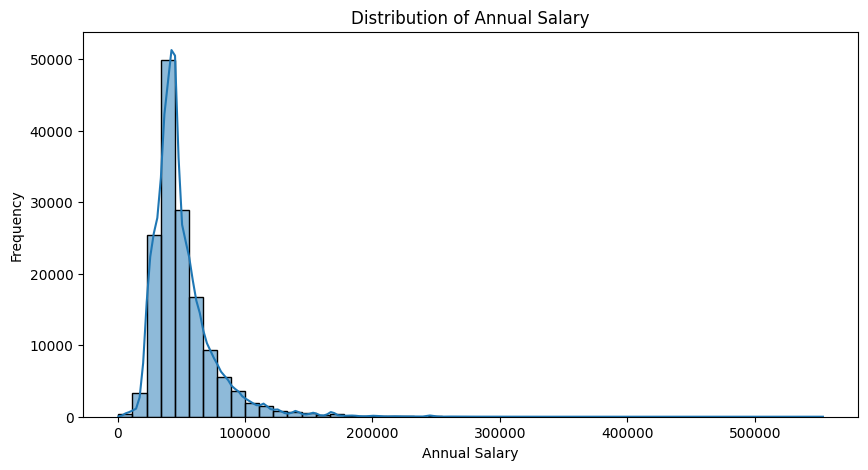

In [ ]:

# Box 24 — Plot salary distribution

plt.figure(figsize=(10, 5))
sns.histplot(df_model["ANNUAL"], bins=50, kde=True)
plt.title("Distribution of Annual Salary")
plt.xlabel("Annual Salary")
plt.ylabel("Frequency")
plt.show()

In [ ]:


# Box 25 — Check extreme salaries

df_model["ANNUAL"].sort_values(ascending=False).head(20)

,ANNUAL
83851,553500.00
144232,450000.00
14793,450000.00
15154,391999.92
136727,384375.00
15041,355141.44
15539,344000.04
84769,343999.92
144262,316116.96
15349,315000.00


In [ ]:
#  Box 27 — Separate features and target

X = df_model[features].copy()
y = df_model[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (149338, 7)
y shape: (149338,)


In [ ]:

# Box 28 — Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 119470
Testing samples: 29868


In [ ]:
y_train_log = np.log1p(y_train)

print("Original target:")
print(y_train.head())

print("\nLog-transformed target:")
print(y_train_log.head())

Original target:
129516    44642.04
27113     53241.96
135857    39411.24
7719      39795.36
90684     55440.00
Name: ANNUAL, dtype: float64

Log-transformed target:
129516    10.706454
27113     10.882621
135857    10.581832
7719      10.591531
90684     10.923075
Name: ANNUAL, dtype: float64


In [ ]:

# Box 30 — Target encoding function
def kfold_target_encode(
    X_train,
    y_train_log,
    X_test,
    categorical_cols,
    n_splits=5,
    smoothing=10,
    random_state=42
):
    X_train_encoded = X_train.copy()
    X_test_encoded = X_test.copy()

    global_mean = y_train_log.mean()

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    for col in categorical_cols:

        train_encoded = pd.Series(
            index=X_train.index,
            dtype=float
        )

        for train_idx, valid_idx in kf.split(X_train):

            fold_train_idx = X_train.index[train_idx]
            fold_valid_idx = X_train.index[valid_idx]

            temp = pd.DataFrame({
                "category": X_train.loc[fold_train_idx, col],
                "target": y_train_log.loc[fold_train_idx]
            })

            stats = temp.groupby("category")["target"].agg(
                ["mean", "count"]
            )

            smooth_mean = (
                (stats["mean"] * stats["count"] +
                 global_mean * smoothing)
                /
                (stats["count"] + smoothing)
            )

            train_encoded.loc[fold_valid_idx] = (
                X_train.loc[fold_valid_idx, col]
                .map(smooth_mean)
                .fillna(global_mean)
            )

        X_train_encoded[col + "_TE"] = train_encoded

        # Final mapping fitted on COMPLETE training data
        temp = pd.DataFrame({
            "category": X_train[col],
            "target": y_train_log
        })

        stats = temp.groupby("category")["target"].agg(
            ["mean", "count"]
        )

        smooth_mean = (
            (stats["mean"] * stats["count"] +
             global_mean * smoothing)
            /
            (stats["count"] + smoothing)
        )

        X_test_encoded[col + "_TE"] = (
            X_test[col]
            .map(smooth_mean)
            .fillna(global_mean)
        )

        X_train_encoded.drop(columns=[col], inplace=True)
        X_test_encoded.drop(columns=[col], inplace=True)

    return X_train_encoded, X_test_encoded


In [ ]:
# Box 31 — Apply it
target_encode_cols = [
    "AGENCY NAME",
    "base_title"
]

X_train_te, X_test_te = kfold_target_encode(
    X_train,
    y_train_log,
    X_test,
    categorical_cols=target_encode_cols,
    n_splits=5,
    smoothing=10,
    random_state=42
)


In [ ]:
# Box 32 — Check the result
print("Training shape:", X_train_te.shape)
print("Testing shape:", X_test_te.shape)

X_train_te.head()

Training shape: (119470, 7)
Testing shape: (29868, 7)


,level,ETHNICITY,GENDER,STATUS,tenure_years,AGENCY NAME_TE,base_title_TE
129516,V,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,18.20,10.603856,10.622692
27113,NA,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,2.81,10.937736,11.068906
135857,IV,ASIAN,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,1.98,10.602106,10.623314
7719,III,BLACK,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,4.84,11.078012,10.673992
90684,III,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,2.29,10.879064,10.922613


In [ ]:
# Box 33 — One-hot encode remaining categorical features

one_hot_cols = [
    "level",
    "ETHNICITY",
    "GENDER",
    "STATUS"
]

X_train_encoded = pd.get_dummies(
    X_train_te,
    columns=one_hot_cols,
    drop_first=False
)

X_test_encoded = pd.get_dummies(
    X_test_te,
    columns=one_hot_cols,
    drop_first=False
)


X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

In [ ]:
# Box 34 — Check the final encoded data

print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

print("\nData types:")
print(X_train_encoded.dtypes)

X_train_encoded.head()


Training shape: (119470, 28)
Testing shape: (29868, 28)

Data types:
tenure_years                                       float64
AGENCY NAME_TE                                     float64
base_title_TE                                      float64
level_I                                               bool
level_II                                              bool
level_III                                             bool
level_IV                                              bool
level_NA                                              bool
level_V                                               bool
level_VI                                              bool
level_VII                                             bool
ETHNICITY_AM INDIAN                                   bool
ETHNICITY_ASIAN                                       bool
ETHNICITY_BLACK                                       bool
ETHNICITY_HISPANIC                                    bool
ETHNICITY_OTHER                               

,tenure_years,AGENCY NAME_TE,base_title_TE,level_I,level_II,level_III,level_IV,level_NA,level_V,level_VI,...,GENDER_MALE,STATUS_CRF - CLASSIFIED REGULAR FULL-TIME,STATUS_CRP - CLASSIFIED REGULAR PART-TIME,STATUS_CTF - CLASSIFIED TEMPORARY FULL-TIME,STATUS_CTP - CLASSIFIED TEMPORARY PART-TIME,STATUS_ERF - EXEMPT REGULAR FULL-TIME,STATUS_URF - UNCLASSIFIED REGULAR FULL-TIME,STATUS_URP - UNCLASSIFIED REGULAR PART-TIME,STATUS_UTF - UNCLASSIFIED TEMPORARY FULL-TIME,STATUS_UTP - UNCLASSIFIED TEMPORARY PART-TIME
129516,18.20,10.603856,10.622692,False,False,False,False,False,True,False,...,False,True,False,False,False,False,False,False,False,False
27113,2.81,10.937736,11.068906,False,False,False,False,True,False,False,...,True,True,False,False,False,False,False,False,False,False
135857,1.98,10.602106,10.623314,False,False,False,True,False,False,False,...,True,True,False,False,False,False,False,False,False,False
7719,4.84,11.078012,10.673992,False,False,True,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
90684,2.29,10.879064,10.922613,False,False,True,False,False,False,False,...,True,True,False,False,False,False,False,False,False,False


In [ ]:

# Box 35 — Check for missing values

print("Training missing values:", X_train_encoded.isnull().sum().sum())
print("Testing missing values:", X_test_encoded.isnull().sum().sum())


Training missing values: 0
Testing missing values: 0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)


In [ ]:
# Box 37 — Convert back to DataFrame
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train_encoded.columns,
    index=X_train_encoded.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test_encoded.columns,
    index=X_test_encoded.index
)

In [ ]:

# Box 38 — Final check
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining mean:")
print(X_train_scaled.mean().abs().max())

print("\nTraining standard deviation:")
print(X_train_scaled.std().mean())

Training shape: (119470, 28)
Testing shape: (29868, 28)

Training mean:
6.235433288906037e-15

Training standard deviation:
1.0000041851773362


In [ ]:
# ADDED CV ONE after lasso
def leakage_safe_cv(
    X,
    y_log,
    model_class,
    model_params=None,
    scale=False,
    n_splits=5,
    smoothing=10,
    random_state=42
):
    if model_params is None:
        model_params = {}

    target_encode_cols = [
        "AGENCY NAME",
        "base_title"
    ]

    one_hot_cols = [
        "level",
        "ETHNICITY",
        "GENDER",
        "STATUS"
    ]

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    cv_rmse = []
    cv_mae = []
    cv_r2 = []

    for outer_train_idx, outer_val_idx in kf.split(X):

        X_outer_train = X.iloc[outer_train_idx].copy()
        X_outer_val = X.iloc[outer_val_idx].copy()

        y_outer_train = y_log.iloc[outer_train_idx].copy()
        y_outer_val = y_log.iloc[outer_val_idx].copy()

        global_mean = y_outer_train.mean()


        X_train_encoded = X_outer_train.copy()
        X_val_encoded = X_outer_val.copy()

        inner_kf = KFold(
            n_splits=5,
            shuffle=True,
            random_state=random_state
        )

        for col in target_encode_cols:

            oof_encoded = pd.Series(
                index=X_outer_train.index,
                dtype=float
            )

            # OOF encoding for outer training data
            for inner_train_idx, inner_val_idx in inner_kf.split(
                X_outer_train
            ):

                inner_train_index = X_outer_train.index[inner_train_idx]
                inner_val_index = X_outer_train.index[inner_val_idx]

                temp = pd.DataFrame({
                    "category": X_outer_train.loc[
                        inner_train_index, col
                    ],
                    "target": y_outer_train.loc[
                        inner_train_index
                    ]
                })

                stats = temp.groupby("category")["target"].agg(
                    ["mean", "count"]
                )

                smooth_mean = (
                    (
                        stats["mean"] * stats["count"]
                        +
                        global_mean * smoothing
                    )
                    /
                    (stats["count"] + smoothing)
                )

                oof_encoded.loc[inner_val_index] = (
                    X_outer_train.loc[
                        inner_val_index, col
                    ]
                    .map(smooth_mean)
                    .fillna(global_mean)
                )

            X_train_encoded[col + "_TE"] = oof_encoded

            # -----------------------------------------
            # VALIDATION ENCODING
            # Fit mapping ONLY on outer training data
            # -----------------------------------------

            temp = pd.DataFrame({
                "category": X_outer_train[col],
                "target": y_outer_train
            })

            stats = temp.groupby("category")["target"].agg(
                ["mean", "count"]
            )

            smooth_mean = (
                (
                    stats["mean"] * stats["count"]
                    +
                    global_mean * smoothing
                )
                /
                (stats["count"] + smoothing)
            )

            X_val_encoded[col + "_TE"] = (
                X_outer_val[col]
                .map(smooth_mean)
                .fillna(global_mean)
            )

            X_train_encoded.drop(columns=[col], inplace=True)
            X_val_encoded.drop(columns=[col], inplace=True)

        # -----------------------------------------
        # ONE-HOT ENCODING
        # -----------------------------------------

        X_train_encoded = pd.get_dummies(
            X_train_encoded,
            columns=one_hot_cols,
            drop_first=False
        )

        X_val_encoded = pd.get_dummies(
            X_val_encoded,
            columns=one_hot_cols,
            drop_first=False
        )


        X_train_encoded, X_val_encoded = X_train_encoded.align(
            X_val_encoded,
            join="left",
            axis=1,
            fill_value=0
        )

        # -----------------------------------------
        # SCALING
        # -----------------------------------------

        if scale:

            fold_scaler = StandardScaler()

            X_train_encoded = pd.DataFrame(
                fold_scaler.fit_transform(X_train_encoded),
                columns=X_train_encoded.columns,
                index=X_train_encoded.index
            )

            X_val_encoded = pd.DataFrame(
                fold_scaler.transform(X_val_encoded),
                columns=X_val_encoded.columns,
                index=X_val_encoded.index
            )

        # -----------------------------------------
        # MODEL
        # -----------------------------------------

        model = model_class(**model_params)

        model.fit(
            X_train_encoded,
            y_outer_train
        )

        # Prediction in log scale
        val_pred_log = model.predict(
            X_val_encoded
        )

        # Convert back to dollars
        val_pred = np.expm1(val_pred_log)
        y_val_original = np.expm1(y_outer_val)

        # -----------------------------------------
        # METRICS
        # -----------------------------------------

        cv_rmse.append(
            np.sqrt(
                mean_squared_error(
                    y_val_original,
                    val_pred
                )
            )
        )

        cv_mae.append(
            mean_absolute_error(
                y_val_original,
                val_pred
            )
        )

        cv_r2.append(
            r2_score(
                y_val_original,
                val_pred
            )
        )

    return {
        "cv_rmse": np.mean(cv_rmse),
        "cv_mae": np.mean(cv_mae),
        "cv_r2": np.mean(cv_r2)
}

In [ ]:
#Box 39 — Import and create the model
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()


In [ ]:
#Box 40 — K-Fold Cross-Validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_rmse = []
cv_mae = []
cv_r2 = []

for train_idx, val_idx in kf.split(X_train_scaled):

    X_fold_train = X_train_scaled.iloc[train_idx]
    X_fold_val = X_train_scaled.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train_log.iloc[val_idx]

    model = LinearRegression()

    model.fit(X_fold_train, y_fold_train)

    val_pred_log = model.predict(X_fold_val)

    # Convert predictions back to dollar scale
    val_pred = np.expm1(val_pred_log)
    y_val_original = np.expm1(y_fold_val)

    cv_rmse.append(
        np.sqrt(mean_squared_error(y_val_original, val_pred))
    )

    cv_mae.append(
        mean_absolute_error(y_val_original, val_pred)
    )

    cv_r2.append(
        r2_score(y_val_original, val_pred)
    )

print("CV RMSE:", np.mean(cv_rmse))
print("CV MAE :", np.mean(cv_mae))
print("CV R²  :", np.mean(cv_r2))

CV RMSE: 10274.867927637823
CV MAE : 5249.089892776794
CV R²  : 0.8330588719739127


In [ ]:
# Box 41 — Train final Linear Regression
linear_model.fit(X_train_scaled, y_train_log)

LinearRegression()

In [ ]:

# Box 42 — Predict on test set
test_pred_log = linear_model.predict(X_test_scaled)

# Convert predictions back to original dollar scale
test_pred = np.expm1(test_pred_log)

In [ ]:

# Box 43 — Calculate final test metrics
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_mae = mean_absolute_error(y_test, test_pred)
test_r2 = r2_score(y_test, test_pred)

print("Linear Regression — Test Results")
print("--------------------------------")
print(f"RMSE: ${test_rmse:,.2f}")
print(f"MAE : ${test_mae:,.2f}")
print(f"R²  : {test_r2:.4f}")

Linear Regression — Test Results
--------------------------------
RMSE: $9,900.36
MAE : $5,183.31
R²  : 0.8416


In [ ]:

#Box 44 — Compare actual vs predicted
comparison = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": test_pred
})

comparison["Absolute Error"] = (
    comparison["Actual Salary"] -
    comparison["Predicted Salary"]
).abs()

comparison.head(20)

,Actual Salary,Predicted Salary,Absolute Error
27982,80417.40,80194.876743,222.523257
126227,31104.60,35030.601141,3926.001141
85839,44496.00,49691.072776,5195.072776
147061,42702.00,50854.017125,8152.017125
99842,43049.04,46989.749329,3940.709329
5249,42000.00,42773.610817,773.610817
93965,46357.92,59662.979893,13305.059893
82800,72150.60,79496.526568,7345.926568
75556,50379.84,49712.278715,667.561285
72909,57913.08,69594.492335,11681.412335


In [ ]:
model_results = []

model_results.append({
    "Model": "Linear Regression",
    "CV RMSE": np.mean(cv_rmse),
    "CV MAE": np.mean(cv_mae),
    "CV R2": np.mean(cv_r2),
    "Test RMSE": test_rmse,
    "Test MAE": test_mae,
    "Test R2": test_r2
})

pd.DataFrame(model_results)

In [ ]:
# Box 46 — Initialize MLflow experiment
import mlflow
import mlflow.sklearn

mlflow.set_experiment("Texas_Salary_Prediction")



2026/08/14 10:54:37 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/14 10:54:37 INFO mlflow.store.db.utils: Updating database tables
2026/08/14 10:54:39 INFO mlflow.tracking.fluent: Experiment with name 'Texas_Salary_Prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1786704879759, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1786704879759, lifecycle_stage='active', name='Texas_Salary_Prediction', tags={}, trace_location=None, workspace='default'>

In [ ]:
# Box 47 — Log Linear Regression run
with mlflow.start_run(run_name="Linear_Regression"):

    # Parameters
    mlflow.log_param("model", "Linear Regression")
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("target_encoded_columns", "AGENCY NAME, base_title")
    mlflow.log_param("one_hot_columns", "level, ETHNICITY, GENDER, STATUS")
    mlflow.log_param("scaling", "StandardScaler")
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("random_state", 42)

    # Cross-validation metrics
    mlflow.log_metric("cv_rmse", np.mean(cv_rmse))
    mlflow.log_metric("cv_mae", np.mean(cv_mae))
    mlflow.log_metric("cv_r2", np.mean(cv_r2))

    # Test metrics
    mlflow.log_metric("test_rmse", test_rmse)
    mlflow.log_metric("test_mae", test_mae)
    mlflow.log_metric("test_r2", test_r2)

    # Log trained model
    mlflow.sklearn.log_model(
        linear_model,
        "linear_regression_model"
    )

    print("Linear Regression logged successfully to MLflow.")

2026/08/14 10:55:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Linear Regression logged successfully to MLflow.


In [ ]:
runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]

,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.8416


In [ ]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)
# Box 50 — Cross-validation
ridge_cv_rmse = []
ridge_cv_mae = []
ridge_cv_r2 = []

for train_idx, val_idx in kf.split(X_train_scaled):

    X_fold_train = X_train_scaled.iloc[train_idx]
    X_fold_val = X_train_scaled.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train_log.iloc[val_idx]

    model = Ridge(alpha=1.0)

    model.fit(X_fold_train, y_fold_train)

    val_pred_log = model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    y_val_original = np.expm1(y_fold_val)

    ridge_cv_rmse.append(
        np.sqrt(mean_squared_error(y_val_original, val_pred))
    )

    ridge_cv_mae.append(
        mean_absolute_error(y_val_original, val_pred)
    )

    ridge_cv_r2.append(
        r2_score(y_val_original, val_pred)
    )

print("Ridge CV RMSE:", np.mean(ridge_cv_rmse))
print("Ridge CV MAE :", np.mean(ridge_cv_mae))
print("Ridge CV R²  :", np.mean(ridge_cv_r2))

Ridge CV RMSE: 10274.92517276478
Ridge CV MAE : 5249.095876689974
Ridge CV R²  : 0.8330570145850199


In [ ]:
ridge_model.fit(X_train_scaled, y_train_log)


Ridge()

In [ ]:
# Box 52 — Test prediction
ridge_test_pred_log = ridge_model.predict(X_test_scaled)

ridge_test_pred = np.expm1(ridge_test_pred_log)


In [ ]:
# Box 53 — Test metrics
ridge_test_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_test_pred)
)

ridge_test_mae = mean_absolute_error(
    y_test,
    ridge_test_pred
)

ridge_test_r2 = r2_score(
    y_test,
    ridge_test_pred
)

print("Ridge Regression — Test Results")
print("--------------------------------")
print(f"RMSE: ${ridge_test_rmse:,.2f}")
print(f"MAE : ${ridge_test_mae:,.2f}")
print(f"R²  : {ridge_test_r2:.4f}")


Ridge Regression — Test Results
--------------------------------
RMSE: $9,900.41
MAE : $5,183.31
R²  : 0.8416


In [ ]:
# Box 54 — Add Ridge to comparison results
model_results.append({
    "Model": "Ridge Regression",
    "CV RMSE": np.mean(ridge_cv_rmse),
    "CV MAE": np.mean(ridge_cv_mae),
    "CV R2": np.mean(ridge_cv_r2),
    "Test RMSE": ridge_test_rmse,
    "Test MAE": ridge_test_mae,
    "Test R2": ridge_test_r2
})

pd.DataFrame(model_results)

,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.40647,5183.314337,0.841599


In [ ]:
#Box 55 — MLflow: Ridge
with mlflow.start_run(run_name="Ridge_Regression"):

    mlflow.log_param("model", "Ridge Regression")
    mlflow.log_param("alpha", 1.0)
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("target_encoded_columns", "AGENCY NAME, base_title")
    mlflow.log_param(
        "one_hot_columns",
        "level, ETHNICITY, GENDER, STATUS"
    )
    mlflow.log_param("scaling", "StandardScaler")
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("random_state", 42)

    mlflow.log_metric("cv_rmse", np.mean(ridge_cv_rmse))
    mlflow.log_metric("cv_mae", np.mean(ridge_cv_mae))
    mlflow.log_metric("cv_r2", np.mean(ridge_cv_r2))

    mlflow.log_metric("test_rmse", ridge_test_rmse)
    mlflow.log_metric("test_mae", ridge_test_mae)
    mlflow.log_metric("test_r2", ridge_test_r2)

    mlflow.sklearn.log_model(
        ridge_model,
        "ridge_regression_model"
    )

    print("Ridge Regression logged successfully to MLflow.")


2026/08/14 11:07:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Ridge Regression logged successfully to MLflow.


In [ ]:
#Box 56 — Verify both runs
runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]

,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600


In [ ]:

#Box 57 — Import and create Lasso

from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.001, max_iter=10000)

# I'm using a small alpha because your features are already standardized and we don't want Lasso to aggressively eliminate useful salary predictors.


In [ ]:

#Box 58 — 5-Fold Cross-Validation

lasso_cv_rmse = []
lasso_cv_mae = []
lasso_cv_r2 = []

for train_idx, val_idx in kf.split(X_train_scaled):

    X_fold_train = X_train_scaled.iloc[train_idx]
    X_fold_val = X_train_scaled.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train_log.iloc[val_idx]

    model = Lasso(
        alpha=0.001,
        max_iter=10000
    )

    model.fit(X_fold_train, y_fold_train)

    val_pred_log = model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    y_val_original = np.expm1(y_fold_val)

    lasso_cv_rmse.append(
        np.sqrt(mean_squared_error(y_val_original, val_pred))
    )

    lasso_cv_mae.append(
        mean_absolute_error(y_val_original, val_pred)
    )

    lasso_cv_r2.append(
        r2_score(y_val_original, val_pred)
    )

print("Lasso CV RMSE:", np.mean(lasso_cv_rmse))
print("Lasso CV MAE :", np.mean(lasso_cv_mae))
print("Lasso CV R²  :", np.mean(lasso_cv_r2))

Lasso CV RMSE: 10276.203057616756
Lasso CV MAE : 5231.133375816562
Lasso CV R²  : 0.8330151510414238


In [ ]:
#Box 59 — Train final Lasso
lasso_model.fit(X_train_scaled, y_train_log)


Lasso(alpha=0.001, max_iter=10000)

In [ ]:
#Box 60 — Test prediction
lasso_test_pred_log = lasso_model.predict(X_test_scaled)

lasso_test_pred = np.expm1(lasso_test_pred_log)


In [ ]:
#Box 61 — Test metrics
lasso_test_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_test_pred)
)

lasso_test_mae = mean_absolute_error(
    y_test,
    lasso_test_pred
)

lasso_test_r2 = r2_score(
    y_test,
    lasso_test_pred
)

print("Lasso Regression — Test Results")
print("--------------------------------")
print(f"RMSE: ${lasso_test_rmse:,.2f}")
print(f"MAE : ${lasso_test_mae:,.2f}")
print(f"R²  : {lasso_test_r2:.4f}")


Lasso Regression — Test Results
--------------------------------
RMSE: $9,892.27
MAE : $5,161.72
R²  : 0.8419


In [ ]:
#Box 62 — Add Lasso to model comparison
model_results.append({
    "Model": "Lasso Regression",
    "CV RMSE": np.mean(lasso_cv_rmse),
    "CV MAE": np.mean(lasso_cv_mae),
    "CV R2": np.mean(lasso_cv_r2),
    "Test RMSE": lasso_test_rmse,
    "Test MAE": lasso_test_mae,
    "Test R2": lasso_test_r2
})

pd.DataFrame(model_results)

,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859


In [ ]:
#Box 63 — Log Lasso in MLflow
with mlflow.start_run(run_name="Lasso_Regression"):

    mlflow.log_param("model", "Lasso Regression")
    mlflow.log_param("alpha", 0.001)
    mlflow.log_param("max_iter", 10000)
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("target_encoded_columns", "AGENCY NAME, base_title")
    mlflow.log_param(
        "one_hot_columns",
        "level, ETHNICITY, GENDER, STATUS"
    )
    mlflow.log_param("scaling", "StandardScaler")
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("random_state", 42)

    mlflow.log_metric("cv_rmse", np.mean(lasso_cv_rmse))
    mlflow.log_metric("cv_mae", np.mean(lasso_cv_mae))
    mlflow.log_metric("cv_r2", np.mean(lasso_cv_r2))

    mlflow.log_metric("test_rmse", lasso_test_rmse)
    mlflow.log_metric("test_mae", lasso_test_mae)
    mlflow.log_metric("test_r2", lasso_test_r2)

    mlflow.sklearn.log_model(
        lasso_model,
        "lasso_regression_model"
    )

    print("Lasso Regression logged successfully to MLflow.")


2026/08/14 11:12:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Lasso Regression logged successfully to MLflow.


In [ ]:
#Box 64 — Verify MLflow
runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]

,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,Lasso_Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
1,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
2,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600


In [ ]:
#Box 41 — Import Decision Tree
from sklearn.tree import DecisionTreeRegressor

decision_tree_model = DecisionTreeRegressor(
    random_state=42
)

In [ ]:

#Box 42 — Leakage-safe CV for Decision Tree
# Use the same leakage_safe_cv() function we just created.
dt_cv_results = leakage_safe_cv(
    X=X_train,
    y_log=y_train_log,
    model_class=DecisionTreeRegressor,
    model_params={
        "random_state": 42
    },
    scale=False,
    n_splits=5,
    smoothing=10,
    random_state=42
)

print("Decision Tree CV Results")
print("------------------------")
print(f"CV RMSE: ${dt_cv_results['cv_rmse']:,.2f}")
print(f"CV MAE : ${dt_cv_results['cv_mae']:,.2f}")
print(f"CV R²  : {dt_cv_results['cv_r2']:.4f}")

Decision Tree CV Results
------------------------
CV RMSE: $10,467.27
CV MAE : $4,421.83
CV R²  : 0.8268


In [ ]:


#Box 43 — Train final Decision Tree

decision_tree_model.fit(
    X_train_encoded,
    y_train_log
)


DecisionTreeRegressor(random_state=42)

In [ ]:

# Box 44 — Test prediction

dt_test_pred_log = decision_tree_model.predict(
    X_test_encoded
)

dt_test_pred = np.expm1(dt_test_pred_log)


In [ ]:

# Box 45 — Test metrics

dt_test_rmse = np.sqrt(
    mean_squared_error(y_test, dt_test_pred)
)

dt_test_mae = mean_absolute_error(
    y_test,
    dt_test_pred
)

dt_test_r2 = r2_score(
    y_test,
    dt_test_pred
)

print("Decision Tree — Test Results")
print("----------------------------")
print(f"RMSE: ${dt_test_rmse:,.2f}")
print(f"MAE : ${dt_test_mae:,.2f}")
print(f"R²  : {dt_test_r2:.4f}")


Decision Tree — Test Results
----------------------------
RMSE: $9,769.69
MAE : $4,366.88
R²  : 0.8458


In [ ]:

# Box 46 — Add to comparison

model_results.append({
    "Model": "Decision Tree",
    "CV RMSE": dt_cv_results["cv_rmse"],
    "CV MAE": dt_cv_results["cv_mae"],
    "CV R2": dt_cv_results["cv_r2"],
    "Test RMSE": dt_test_rmse,
    "Test MAE": dt_test_mae,
    "Test R2": dt_test_r2
})

pd.DataFrame(model_results)


,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
2,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754


In [ ]:
#Box 47-MLFLOW:Decision tree
with mlflow.start_run(run_name="Decision_Tree"):

    mlflow.log_param("model", "Decision Tree Regressor")
    mlflow.log_param("random_state", 42)
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("target_encoded_columns", "AGENCY NAME, base_title")
    mlflow.log_param(
        "one_hot_columns",
        "level, ETHNICITY, GENDER, STATUS"
    )
    mlflow.log_param("scaling", "None")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("cv_rmse", dt_cv_results["cv_rmse"])
    mlflow.log_metric("cv_mae", dt_cv_results["cv_mae"])
    mlflow.log_metric("cv_r2", dt_cv_results["cv_r2"])

    mlflow.log_metric("test_rmse", dt_test_rmse)
    mlflow.log_metric("test_mae", dt_test_mae)
    mlflow.log_metric("test_r2", dt_test_r2)

    mlflow.sklearn.log_model(
        decision_tree_model,
        "decision_tree_model"
    )

    print("Decision Tree logged successfully to MLflow.")



2026/08/14 11:27:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Decision Tree logged successfully to MLflow.


In [ ]:
#Box 48-verify ML flow
runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]

,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,Decision_Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
1,Lasso_Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
2,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
3,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600


In [ ]:

#Box 49 — Import and create Random Forest

from sklearn.ensemble import RandomForestRegressor

random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)


In [ ]:

#Box 50 — Leakage-safe CV

rf_cv_results = leakage_safe_cv(
    X=X_train,
    y_log=y_train_log,
    model_class=RandomForestRegressor,
    model_params={
        "n_estimators": 200,
        "random_state": 42,
        "n_jobs": -1
    },
    scale=False,
    n_splits=5,
    smoothing=10,
    random_state=42
)

print("Random Forest CV Results")
print("------------------------")
print(f"CV RMSE: ${rf_cv_results['cv_rmse']:,.2f}")
print(f"CV MAE : ${rf_cv_results['cv_mae']:,.2f}")
print(f"CV R²  : {rf_cv_results['cv_r2']:.4f}")

Random Forest CV Results
------------------------
CV RMSE: $7,766.73
CV MAE : $3,454.29
CV R²  : 0.9046


In [ ]:

#Box 51

random_forest_model.fit(
    X_train_encoded,
    y_train_log
)


RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:

#Box 52 — Test prediction

rf_test_pred_log = random_forest_model.predict(
    X_test_encoded
)

rf_test_pred = np.expm1(rf_test_pred_log)


In [ ]:

#Box 53 — Test metrics

rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_test_pred)
)

rf_test_mae = mean_absolute_error(
    y_test,
    rf_test_pred
)

rf_test_r2 = r2_score(
    y_test,
    rf_test_pred
)

print("Random Forest — Test Results")
print("----------------------------")
print(f"RMSE: ${rf_test_rmse:,.2f}")
print(f"MAE : ${rf_test_mae:,.2f}")
print(f"R²  : {rf_test_r2:.4f}")


Random Forest — Test Results
----------------------------
RMSE: $7,549.96
MAE : $3,476.88
R²  : 0.9079


In [ ]:

#Box 54 — Add to comparison

model_results.append({
    "Model": "Random Forest",
    "CV RMSE": rf_cv_results["cv_rmse"],
    "CV MAE": rf_cv_results["cv_mae"],
    "CV R2": rf_cv_results["cv_r2"],
    "Test RMSE": rf_test_rmse,
    "Test MAE": rf_test_mae,
    "Test R2": rf_test_r2
})

pd.DataFrame(model_results)

,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
2,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
3,Random Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883


In [ ]:
#Box 55 — MLflow: Random Forest

with mlflow.start_run(run_name="Random_Forest"):

    mlflow.log_param("model", "Random Forest Regressor")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("n_jobs", -1)
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("target_encoded_columns", "AGENCY NAME, base_title")
    mlflow.log_param(
        "one_hot_columns",
        "level, ETHNICITY, GENDER, STATUS"
    )
    mlflow.log_param("scaling", "None")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("cv_rmse", rf_cv_results["cv_rmse"])
    mlflow.log_metric("cv_mae", rf_cv_results["cv_mae"])
    mlflow.log_metric("cv_r2", rf_cv_results["cv_r2"])

    mlflow.log_metric("test_rmse", rf_test_rmse)
    mlflow.log_metric("test_mae", rf_test_mae)
    mlflow.log_metric("test_r2", rf_test_r2)

    mlflow.sklearn.log_model(
        random_forest_model,
        "random_forest_model"
    )

    print("Random Forest logged successfully to MLflow.")


2026/08/14 11:57:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Random Forest logged successfully to MLflow.


In [ ]:

#Box 56 — Verify MLflow

runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]

,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,Random_Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
1,Decision_Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
2,Lasso_Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
3,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
4,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600


In [ ]:
#Box 57 — Import and create Gradient Boosting
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)


In [ ]:
# Box 58 — Leakage-safe CV
gb_cv_results = leakage_safe_cv(
    X=X_train,
    y_log=y_train_log,
    model_class=GradientBoostingRegressor,
    model_params={
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 3,
        "random_state": 42
    },
    scale=False,
    n_splits=5,
    smoothing=10,
    random_state=42
)

print("Gradient Boosting CV Results")
print("----------------------------")
print(f"CV RMSE: ${gb_cv_results['cv_rmse']:,.2f}")
print(f"CV MAE : ${gb_cv_results['cv_mae']:,.2f}")
print(f"CV R²  : {gb_cv_results['cv_r2']:.4f}")

Gradient Boosting CV Results
----------------------------
CV RMSE: $8,870.30
CV MAE : $4,561.24
CV R²  : 0.8755


In [ ]:

#Box 59 — Final training

gradient_boosting_model.fit(
    X_train_encoded,
    y_train_log
)


GradientBoostingRegressor(learning_rate=0.05, n_estimators=200, random_state=42)

In [ ]:

#Box 60 — Test prediction

gb_test_pred_log = gradient_boosting_model.predict(
    X_test_encoded
)

gb_test_pred = np.expm1(gb_test_pred_log)


In [ ]:

#Box 61 — Test metrics

gb_test_rmse = np.sqrt(
    mean_squared_error(y_test, gb_test_pred)
)

gb_test_mae = mean_absolute_error(
    y_test,
    gb_test_pred
)

gb_test_r2 = r2_score(
    y_test,
    gb_test_pred
)

print("Gradient Boosting — Test Results")
print("--------------------------------")
print(f"RMSE: ${gb_test_rmse:,.2f}")
print(f"MAE : ${gb_test_mae:,.2f}")
print(f"R²  : {gb_test_r2:.4f}")


Gradient Boosting — Test Results
--------------------------------
RMSE: $8,504.84
MAE : $4,509.35
R²  : 0.8831


In [ ]:

#Box 62 — Add to model comparison

model_results.append({
    "Model": "Gradient Boosting",
    "CV RMSE": gb_cv_results["cv_rmse"],
    "CV MAE": gb_cv_results["cv_mae"],
    "CV R2": gb_cv_results["cv_r2"],
    "Test RMSE": gb_test_rmse,
    "Test MAE": gb_test_mae,
    "Test R2": gb_test_r2
})

pd.DataFrame(model_results)

,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
2,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
3,Random Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
4,Gradient Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108


In [ ]:
#Box 63 — MLflow: Gradient Boosting
with mlflow.start_run(run_name="Gradient_Boosting"):

    mlflow.log_param("model", "Gradient Boosting Regressor")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("max_depth", 3)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("target_encoded_columns", "AGENCY NAME, base_title")
    mlflow.log_param(
        "one_hot_columns",
        "level, ETHNICITY, GENDER, STATUS"
    )
    mlflow.log_param("scaling", "None")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("cv_rmse", gb_cv_results["cv_rmse"])
    mlflow.log_metric("cv_mae", gb_cv_results["cv_mae"])
    mlflow.log_metric("cv_r2", gb_cv_results["cv_r2"])

    mlflow.log_metric("test_rmse", gb_test_rmse)
    mlflow.log_metric("test_mae", gb_test_mae)
    mlflow.log_metric("test_r2", gb_test_r2)

    mlflow.sklearn.log_model(
        gradient_boosting_model,
        "gradient_boosting_model"
    )

    print("Gradient Boosting logged successfully to MLflow.")



2026/08/14 12:07:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Gradient Boosting logged successfully to MLflow.


In [ ]:
#Box 64 — Verify
runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]

,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,Gradient_Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
1,Random_Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
2,Decision_Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
3,Lasso_Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
4,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
5,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600


In [ ]:
#Box 65 — Import XGBoost

from xgboost import XGBRegressor

In [ ]:
#Box 66 — Create XGBoost model

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


In [ ]:

#Box 67 — Leakage-safe CV

xgb_cv_results = leakage_safe_cv(
    X=X_train,
    y_log=y_train_log,
    model_class=XGBRegressor,
    model_params={
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": 6,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "objective": "reg:squarederror",
        "random_state": 42,
        "n_jobs": -1
    },
    scale=False,
    n_splits=5,
    smoothing=10,
    random_state=42
)

print("XGBoost CV Results")
print("------------------")
print(f"CV RMSE: ${xgb_cv_results['cv_rmse']:,.2f}")
print(f"CV MAE : ${xgb_cv_results['cv_mae']:,.2f}")
print(f"CV R²  : {xgb_cv_results['cv_r2']:.4f}")

XGBoost CV Results
------------------
CV RMSE: $7,383.05
CV MAE : $3,676.54
CV R²  : 0.9137


In [ ]:

# Box 68 — Final XGBoost training

xgb_model.fit(
    X_train_encoded,
    y_train_log
)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:

# Box 69 — Test prediction

xgb_test_pred_log = xgb_model.predict(
    X_test_encoded
)

xgb_test_pred = np.expm1(xgb_test_pred_log)


In [ ]:

# Box 70 — Test metrics

xgb_test_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_test_pred)
)

xgb_test_mae = mean_absolute_error(
    y_test,
    xgb_test_pred
)

xgb_test_r2 = r2_score(
    y_test,
    xgb_test_pred
)

print("XGBoost — Test Results")
print("----------------------")
print(f"RMSE: ${xgb_test_rmse:,.2f}")
print(f"MAE : ${xgb_test_mae:,.2f}")
print(f"R²  : {xgb_test_r2:.4f}")


XGBoost — Test Results
----------------------
RMSE: $7,097.19
MAE : $3,642.51
R²  : 0.9186


In [ ]:

#Box 71 — Add to comparison

model_results.append({
    "Model": "XGBoost",
    "CV RMSE": xgb_cv_results["cv_rmse"],
    "CV MAE": xgb_cv_results["cv_mae"],
    "CV R2": xgb_cv_results["cv_r2"],
    "Test RMSE": xgb_test_rmse,
    "Test MAE": xgb_test_mae,
    "Test R2": xgb_test_r2
})

pd.DataFrame(model_results)

,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
2,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
3,Random Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
4,Gradient Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
5,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600


In [ ]:
#Box 72 — MLflow: XGBoost

with mlflow.start_run(run_name="XGBoost"):

    mlflow.log_param("model", "XGBoost Regressor")
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("subsample", 0.8)
    mlflow.log_param("colsample_bytree", 0.8)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("scaling", "None")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("cv_rmse", xgb_cv_results["cv_rmse"])
    mlflow.log_metric("cv_mae", xgb_cv_results["cv_mae"])
    mlflow.log_metric("cv_r2", xgb_cv_results["cv_r2"])

    mlflow.log_metric("test_rmse", xgb_test_rmse)
    mlflow.log_metric("test_mae", xgb_test_mae)
    mlflow.log_metric("test_r2", xgb_test_r2)

    mlflow.xgboost.log_model(
        xgb_model,
        "xgboost_model"
    )

    print("XGBoost logged successfully to MLflow.")


2026/08/14 12:14:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


XGBoost logged successfully to MLflow.


In [ ]:

# Box 73 — Verify MLflow

runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]


,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600
1,Gradient_Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
2,Random_Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
3,Decision_Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
4,Lasso_Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
5,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
6,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600


In [ ]:
#Box 74 — Import LightGBM
from lightgbm import LGBMRegressor


In [ ]:
# Box 75 — Create LightGBM model
lightgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)


In [ ]:
# Box 76 — Leakage-safe CV
lgb_cv_results = leakage_safe_cv(
    X=X_train,
    y_log=y_train_log,
    model_class=LGBMRegressor,
    model_params={
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": -1,
        "num_leaves": 31,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    },
    scale=False,
    n_splits=5,
    smoothing=10,
    random_state=42
)

print("LightGBM CV Results")
print("-------------------")
print(f"CV RMSE: ${lgb_cv_results['cv_rmse']:,.2f}")
print(f"CV MAE : ${lgb_cv_results['cv_mae']:,.2f}")
print(f"CV R²  : {lgb_cv_results['cv_r2']:.4f}")

LightGBM CV Results
-------------------
CV RMSE: $7,380.52
CV MAE : $3,702.08
CV R²  : 0.9138


In [ ]:

# Box 77 — Final training

lightgbm_model.fit(
    X_train_encoded,
    y_train_log
)


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.05, n_estimators=300,
              n_jobs=-1, random_state=42, subsample=0.8, verbosity=-1)

In [ ]:

# Box 78 — Test prediction

lgb_test_pred_log = lightgbm_model.predict(
    X_test_encoded
)

lgb_test_pred = np.expm1(lgb_test_pred_log)


In [ ]:

# Box 79 — Test metrics

lgb_test_rmse = np.sqrt(
    mean_squared_error(y_test, lgb_test_pred)
)

lgb_test_mae = mean_absolute_error(
    y_test,
    lgb_test_pred
)

lgb_test_r2 = r2_score(
    y_test,
    lgb_test_pred
)

print("LightGBM — Test Results")
print("-----------------------")
print(f"RMSE: ${lgb_test_rmse:,.2f}")
print(f"MAE : ${lgb_test_mae:,.2f}")
print(f"R²  : {lgb_test_r2:.4f}")


LightGBM — Test Results
-----------------------
RMSE: $7,112.92
MAE : $3,676.68
R²  : 0.9182


In [ ]:

# Box 80 — Add to comparison

model_results.append({
    "Model": "LightGBM",
    "CV RMSE": lgb_cv_results["cv_rmse"],
    "CV MAE": lgb_cv_results["cv_mae"],
    "CV R2": lgb_cv_results["cv_r2"],
    "Test RMSE": lgb_test_rmse,
    "Test MAE": lgb_test_mae,
    "Test R2": lgb_test_r2
})

pd.DataFrame(model_results)

,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
2,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
3,Random Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
4,Gradient Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
5,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600
6,LightGBM,7380.515110,3702.081993,0.913847,7112.923344,3676.677684,0.918239


In [ ]:

# Box 81 — MLflow: LightGBM

with mlflow.start_run(run_name="LightGBM"):

    mlflow.log_param("model", "LightGBM Regressor")
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("max_depth", -1)
    mlflow.log_param("num_leaves", 31)
    mlflow.log_param("subsample", 0.8)
    mlflow.log_param("colsample_bytree", 0.8)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")
    mlflow.log_param("encoding", "K-fold smoothed target encoding")
    mlflow.log_param("scaling", "None")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric("cv_rmse", lgb_cv_results["cv_rmse"])
    mlflow.log_metric("cv_mae", lgb_cv_results["cv_mae"])
    mlflow.log_metric("cv_r2", lgb_cv_results["cv_r2"])

    mlflow.log_metric("test_rmse", lgb_test_rmse)
    mlflow.log_metric("test_mae", lgb_test_mae)
    mlflow.log_metric("test_r2", lgb_test_r2)

    mlflow.lightgbm.log_model(
        lightgbm_model,
        "lightgbm_model"
    )

    print("LightGBM logged successfully to MLflow.")


2026/08/14 12:20:57 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


LightGBM logged successfully to MLflow.


In [ ]:

# Box 82 — Verify

runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]]

,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,LightGBM,7380.515110,3702.081993,0.913847,7112.923344,3676.677684,0.918239
1,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600
2,Gradient_Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
3,Random_Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
4,Decision_Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
5,Lasso_Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
6,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
7,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600


In [ ]:
# Box 83 — Import CatBoost

from catboost import CatBoostRegressor


In [ ]:

# Box 84 — Prepare CatBoost data

catboost_cat_cols = [
    "AGENCY NAME",
    "base_title",
    "level",
    "ETHNICITY",
    "GENDER",
    "STATUS"
]

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in catboost_cat_cols:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Missing").astype(str)

catboost_cat_indices = [
    X_train_cb.columns.get_loc(col)
    for col in catboost_cat_cols
]

print("Categorical columns:", catboost_cat_cols)
print("Categorical indices:", catboost_cat_indices)


Categorical columns: ['AGENCY NAME', 'base_title', 'level', 'ETHNICITY', 'GENDER', 'STATUS']
Categorical indices: [0, 1, 2, 3, 4, 5]


In [ ]:

# Box 85 — Create CatBoost model

catboost_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=7,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)



In [ ]:
# Box 86 — CatBoost 5-Fold CV

# Don't use leakage_safe_cv() here, because that function is specifically built around manual target encoding. CatBoost handles the categorical features itself.

catboost_cv_rmse = []
catboost_cv_mae = []
catboost_cv_r2 = []

kf_cb = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for train_idx, val_idx in kf_cb.split(X_train_cb):

    X_fold_train = X_train_cb.iloc[train_idx]
    X_fold_val = X_train_cb.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train_log.iloc[val_idx]

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=7,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    model.fit(
        X_fold_train,
        y_fold_train,
        cat_features=catboost_cat_indices
    )

    val_pred_log = model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    y_val_original = np.expm1(y_fold_val)

    catboost_cv_rmse.append(
        np.sqrt(
            mean_squared_error(
                y_val_original,
                val_pred
            )
        )
    )

    catboost_cv_mae.append(
        mean_absolute_error(
            y_val_original,
            val_pred
        )
    )

    catboost_cv_r2.append(
        r2_score(
            y_val_original,
            val_pred
        )
    )

print("CatBoost CV Results")
print("-------------------")
print(f"CV RMSE: ${np.mean(catboost_cv_rmse):,.2f}")
print(f"CV MAE : ${np.mean(catboost_cv_mae):,.2f}")
print(f"CV R²  : {np.mean(catboost_cv_r2):.4f}")

CatBoost CV Results
-------------------
CV RMSE: $9,726.91
CV MAE : $4,162.06
CV R²  : 0.8504


In [ ]:

# Box 87 — Train CatBoost model


catboost_model.fit(
    X_train_cb,
    y_train_log,
    cat_features=catboost_cat_indices
)



CatBoostRegressor(depth=7, iterations=500, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=False)

In [ ]:


# Box 88 — Verify that it is trained

print("CatBoost model trained successfully.")




CatBoost model trained successfully.


In [ ]:
# Box 89 — Predict

catboost_test_pred_log = catboost_model.predict(
    X_test_cb
)

catboost_test_pred = np.expm1(
    catboost_test_pred_log
)



In [ ]:
# Box 90 — Test metrics

catboost_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        catboost_test_pred
    )
)

catboost_test_mae = mean_absolute_error(
    y_test,
    catboost_test_pred
)

catboost_test_r2 = r2_score(
    y_test,
    catboost_test_pred
)

print("CatBoost — Test Results")
print("-----------------------")
print(f"RMSE: ${catboost_test_rmse:,.2f}")
print(f"MAE : ${catboost_test_mae:,.2f}")
print(f"R²  : {catboost_test_r2:.4f}")

CatBoost — Test Results
-----------------------
RMSE: $9,266.56
MAE : $4,060.56
R²  : 0.8612


In [ ]:
model_results.append({
    "Model": "CatBoost",
    "CV RMSE": np.mean(catboost_cv_rmse),
    "CV MAE": np.mean(catboost_cv_mae),
    "CV R2": np.mean(catboost_cv_r2),
    "Test RMSE": catboost_test_rmse,
    "Test MAE": catboost_test_mae,
    "Test R2": catboost_test_r2
})

results_df = pd.DataFrame(model_results)

results_df

,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599
1,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
2,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
3,Random Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
4,Gradient Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
5,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600
6,LightGBM,7380.515110,3702.081993,0.913847,7112.923344,3676.677684,0.918239
7,CatBoost,9726.905738,4162.057853,0.850368,9266.558846,4060.561675,0.861232


In [ ]:

# Box 92 — MLflow: CatBoost

with mlflow.start_run(run_name="CatBoost"):

    mlflow.log_param("model", "CatBoost Regressor")
    mlflow.log_param("iterations", 500)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("depth", 7)
    mlflow.log_param("random_seed", 42)

    mlflow.log_param("target", "ANNUAL")
    mlflow.log_param("target_transform", "log1p")

    mlflow.log_param(
        "categorical_features",
        "AGENCY NAME, base_title, level, ETHNICITY, GENDER, STATUS"
    )

    mlflow.log_param("encoding", "CatBoost native categorical handling")
    mlflow.log_param("scaling", "None")
    mlflow.log_param("cv_folds", 5)

    mlflow.log_metric(
        "cv_rmse",
        np.mean(catboost_cv_rmse)
    )

    mlflow.log_metric(
        "cv_mae",
        np.mean(catboost_cv_mae)
    )

    mlflow.log_metric(
        "cv_r2",
        np.mean(catboost_cv_r2)
    )

    mlflow.log_metric(
        "test_rmse",
        catboost_test_rmse
    )

    mlflow.log_metric(
        "test_mae",
        catboost_test_mae
    )

    mlflow.log_metric(
        "test_r2",
        catboost_test_r2
    )

    mlflow.catboost.log_model(
        catboost_model,
        "catboost_model"
    )

    print("CatBoost logged successfully to MLflow.")



2026/08/14 12:43:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


CatBoost logged successfully to MLflow.


In [ ]:
# Box 93 — Final MLflow verification

runs = mlflow.search_runs(
    experiment_names=["Texas_Salary_Prediction"]
)

runs[[
    "tags.mlflow.runName",
    "metrics.cv_rmse",
    "metrics.cv_mae",
    "metrics.cv_r2",
    "metrics.test_rmse",
    "metrics.test_mae",
    "metrics.test_r2"
]].sort_values(
    "metrics.test_rmse"
)


,tags.mlflow.runName,metrics.cv_rmse,metrics.cv_mae,metrics.cv_r2,metrics.test_rmse,metrics.test_mae,metrics.test_r2
2,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600
1,LightGBM,7380.515110,3702.081993,0.913847,7112.923344,3676.677684,0.918239
4,Random_Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
3,Gradient_Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
0,CatBoost,9726.905738,4162.057853,0.850368,9266.558846,4060.561675,0.861232
5,Decision_Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
6,Lasso_Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
8,Linear_Regression,10274.867928,5249.089893,0.833059,9900.360526,5183.310328,0.841600
7,Ridge_Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599


In [ ]:

# Box 94 — Final 9-model comparison

final_results = pd.DataFrame(model_results)

final_results = final_results.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

final_results


,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600
1,LightGBM,7380.515110,3702.081993,0.913847,7112.923344,3676.677684,0.918239
2,Random Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
3,Gradient Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
4,CatBoost,9726.905738,4162.057853,0.850368,9266.558846,4060.561675,0.861232
5,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
6,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
7,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599


In [ ]:

# Box 95 — Clean comparison table

comparison = final_results[
    [
        "Model",
        "CV RMSE",
        "CV MAE",
        "CV R2",
        "Test RMSE",
        "Test MAE",
        "Test R2"
    ]
].copy()

comparison


,Model,CV RMSE,CV MAE,CV R2,Test RMSE,Test MAE,Test R2
0,XGBoost,7383.050389,3676.539773,0.913678,7097.186129,3642.507030,0.918600
1,LightGBM,7380.515110,3702.081993,0.913847,7112.923344,3676.677684,0.918239
2,Random Forest,7766.725189,3454.292742,0.904640,7549.961285,3476.875612,0.907883
3,Gradient Boosting,8870.300755,4561.240592,0.875543,8504.839404,4509.347121,0.883108
4,CatBoost,9726.905738,4162.057853,0.850368,9266.558846,4060.561675,0.861232
5,Decision Tree,10467.271038,4421.831741,0.826768,9769.690070,4366.878925,0.845754
6,Lasso Regression,10276.203058,5231.133376,0.833015,9892.268424,5161.722190,0.841859
7,Ridge Regression,10274.925173,5249.095877,0.833057,9900.406470,5183.314337,0.841599


In [ ]:

# Box 96 — Identify the best model

best_model_row = final_results.loc[
    final_results["Test RMSE"].idxmin()
]

print("Best Model Based on Test RMSE")
print("-----------------------------")
print("Model:", best_model_row["Model"])
print(f"Test RMSE: ${best_model_row['Test RMSE']:,.2f}")
print(f"Test MAE : ${best_model_row['Test MAE']:,.2f}")
print(f"Test R²  : {best_model_row['Test R2']:.4f}")

Best Model Based on Test RMSE
-----------------------------
Model: XGBoost
Test RMSE: $7,097.19
Test MAE : $3,642.51
Test R²  : 0.9186


In [ ]:

# Box 97 — XGBoost Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance.head(20)


,Feature,Importance
0,base_title_TE,0.231431
1,level_I,0.110184
2,STATUS_CRP - CLASSIFIED REGULAR PART-TIME,0.078704
3,level_II,0.064187
4,level_VI,0.053657
5,level_V,0.050272
6,STATUS_CRF - CLASSIFIED REGULAR FULL-TIME,0.047639
7,AGENCY NAME_TE,0.042211
8,STATUS_ERF - EXEMPT REGULAR FULL-TIME,0.040175
9,level_III,0.038706


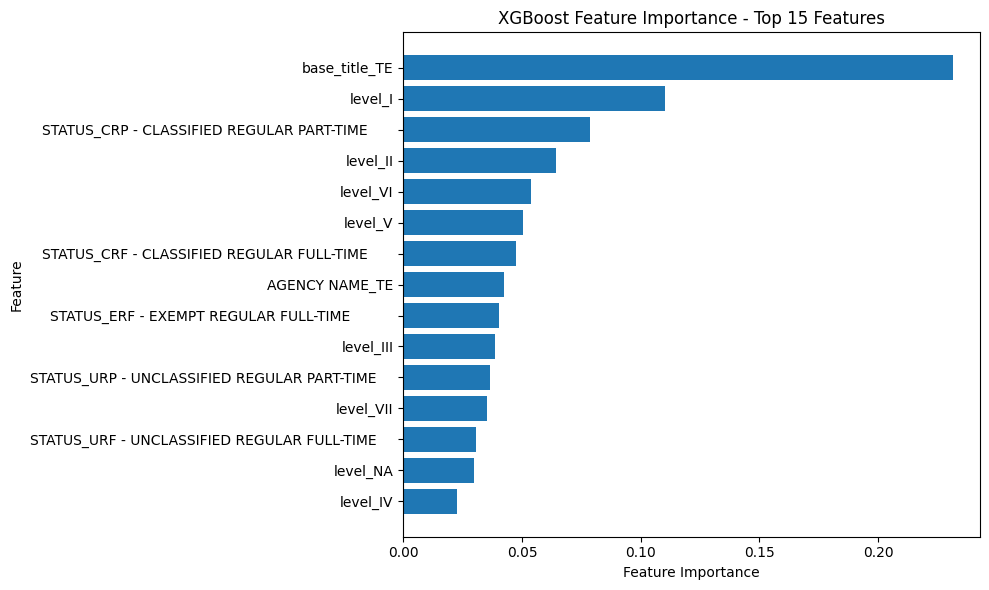

In [ ]:

# Box 98 — Plot top 15 features

import matplotlib.pyplot as plt

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance - Top 15 Features")

plt.tight_layout()
plt.show()

In [ ]:
# Box 99 — Install/import SHAP
!pip install -q shap


In [ ]:


# Box 100 — Create SHAP explainer
import shap
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(
    X_test_encoded
)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (29868, 28)


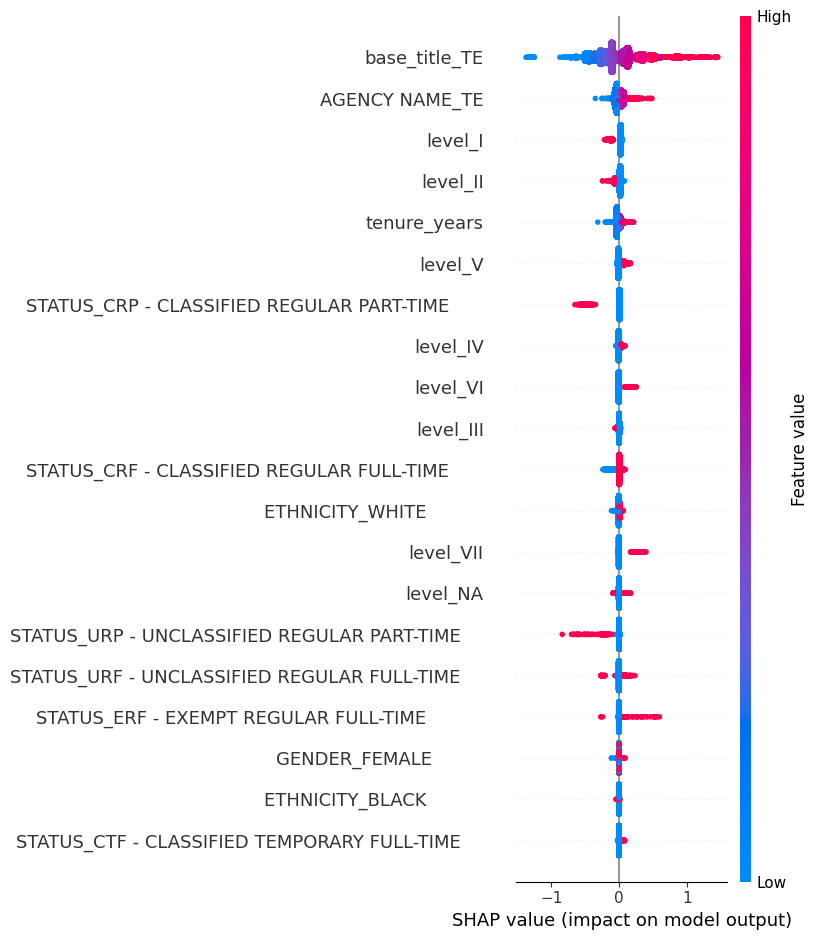

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_encoded,
    max_display=20
)

In [ ]:

# Box 102 — Quantify SHAP contribution

shap_importance = pd.DataFrame({
    "Feature": X_test_encoded.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance.head(20)


,Feature,Mean_Absolute_SHAP
0,base_title_TE,0.248904
1,AGENCY NAME_TE,0.045724
2,level_I,0.042775
3,level_II,0.027886
4,tenure_years,0.027011
5,level_V,0.021085
6,STATUS_CRP - CLASSIFIED REGULAR PART-TIME,0.010827
7,level_IV,0.010347
8,level_VI,0.008616
9,level_III,0.006958


In [ ]:

# Box 103 — Specifically check Gender and Ethnicity

demographic_features = shap_importance[
    shap_importance["Feature"].str.contains(
        "GENDER|ETHNICITY",
        case=False,
        regex=True
    )
]

demographic_features


,Feature,Mean_Absolute_SHAP
11,ETHNICITY_WHITE,0.004268
17,GENDER_FEMALE,0.000845
18,ETHNICITY_BLACK,0.000709
20,ETHNICITY_HISPANIC,0.000484
21,ETHNICITY_ASIAN,0.000470
23,GENDER_MALE,0.000391
25,ETHNICITY_OTHER,0.000025
27,ETHNICITY_AM INDIAN,0.000008


In [ ]:

# Box 104 — Calculate their total SHAP contribution

total_shap = shap_importance["Mean_Absolute_SHAP"].sum()

demographic_shap = demographic_features[
    "Mean_Absolute_SHAP"
].sum()

demographic_percentage = (
    demographic_shap / total_shap
) * 100

print(
    f"Gender + Ethnicity SHAP contribution: "
    f"{demographic_percentage:.2f}%"
)

Gender + Ethnicity SHAP contribution: 1.50%


In [ ]:

# Box 105 — Create test prediction dataframe

fairness_df = X_test.copy()

fairness_df["Actual_Salary"] = y_test.values
fairness_df["Predicted_Salary"] = xgb_test_pred

fairness_df["Absolute_Error"] = np.abs(
    fairness_df["Actual_Salary"] -
    fairness_df["Predicted_Salary"]
)

fairness_df["Error"] = (
    fairness_df["Predicted_Salary"] -
    fairness_df["Actual_Salary"]
)

print("Fairness analysis dataset shape:", fairness_df.shape)


Fairness analysis dataset shape: (29868, 11)


In [ ]:

# Box 106 — Gender fairness

gender_fairness = fairness_df.groupby(
    "GENDER"
).agg(
    Count=("Actual_Salary", "size"),
    Actual_Mean=("Actual_Salary", "mean"),
    Predicted_Mean=("Predicted_Salary", "mean"),
    MAE=("Absolute_Error", "mean"),
    Bias=("Error", "mean")
).reset_index()

gender_fairness

,GENDER,Count,Actual_Mean,Predicted_Mean,MAE,Bias
0,FEMALE,17046,47650.396297,47400.828125,3474.316696,-249.570186
1,MALE,12822,54436.661685,53999.859375,3866.104941,-436.805542


In [ ]:

# Box 107 — Ethnicity fairness

ethnicity_fairness = fairness_df.groupby(
    "ETHNICITY"
).agg(
    Count=("Actual_Salary", "size"),
    Actual_Mean=("Actual_Salary", "mean"),
    Predicted_Mean=("Predicted_Salary", "mean"),
    MAE=("Absolute_Error", "mean"),
    Bias=("Error", "mean")
).reset_index()

ethnicity_fairness

,ETHNICITY,Count,Actual_Mean,Predicted_Mean,MAE,Bias
0,AM INDIAN,122,51630.140656,51698.937500,3149.928590,68.797164
1,ASIAN,866,64643.124804,63800.867188,5670.745822,-842.255511
2,BLACK,7135,43321.401435,43044.128906,2385.445619,-277.272764
3,HISPANIC,8188,47011.726693,46702.386719,3250.665849,-309.341971
4,OTHER,186,45360.883226,45367.503906,3262.893682,6.621363
5,WHITE,13371,55754.122091,55408.304688,4431.660915,-345.815001


In [ ]:
# Box 108 — Calculate fairness disparities

gender_mae_gap = (
    gender_fairness["MAE"].max() -
    gender_fairness["MAE"].min()
)

ethnicity_mae_gap = (
    ethnicity_fairness["MAE"].max() -
    ethnicity_fairness["MAE"].min()
)

gender_bias_gap = (
    gender_fairness["Bias"].max() -
    gender_fairness["Bias"].min()
)

ethnicity_bias_gap = (
    ethnicity_fairness["Bias"].max() -
    ethnicity_fairness["Bias"].min()
)

print("Gender MAE gap: $", round(gender_mae_gap, 2))
print("Ethnicity MAE gap: $", round(ethnicity_mae_gap, 2))

print("Gender Bias gap: $", round(gender_bias_gap, 2))
print("Ethnicity Bias gap: $", round(ethnicity_bias_gap, 2))

Gender MAE gap: $ 391.79
Ethnicity MAE gap: $ 3285.3
Gender Bias gap: $ 187.24
Ethnicity Bias gap: $ 911.05


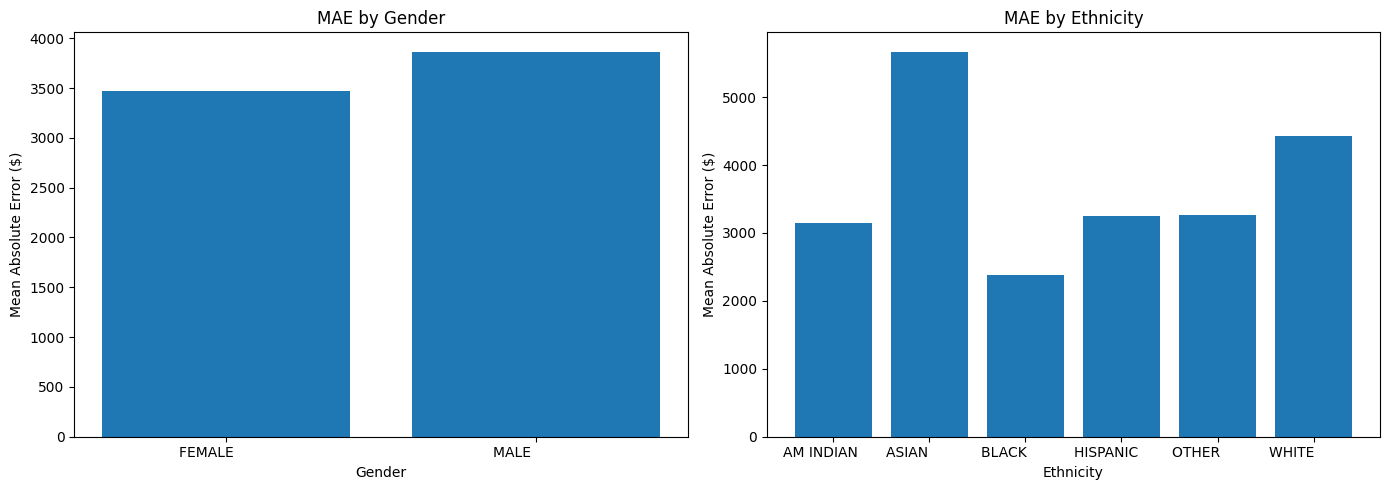

In [ ]:
# Box 109 — Fairness visualization

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender MAE
axes[0].bar(
    gender_fairness["GENDER"],
    gender_fairness["MAE"]
)
axes[0].set_title("MAE by Gender")
axes[0].set_ylabel("Mean Absolute Error ($)")
axes[0].set_xlabel("Gender")

# Ethnicity MAE
axes[1].bar(
    ethnicity_fairness["ETHNICITY"],
    ethnicity_fairness["MAE"]
)
axes[1].set_title("MAE by Ethnicity")
axes[1].set_ylabel("Mean Absolute Error ($)")
axes[1].set_xlabel("Ethnicity")

plt.tight_layout()
plt.show()

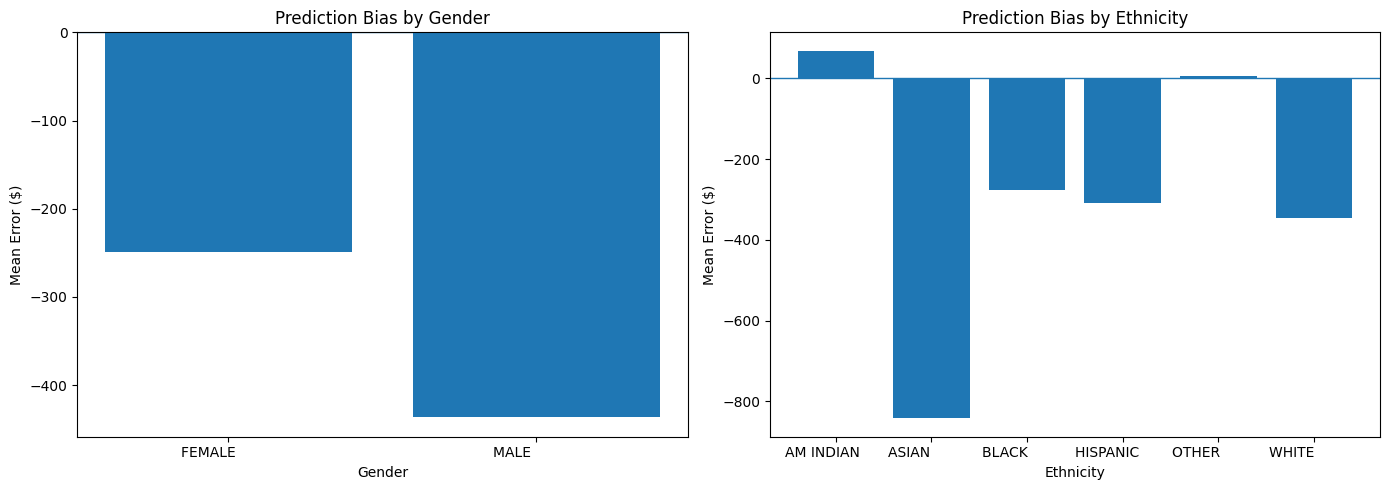

In [ ]:
# Box 110 — Bias by Gender and Ethnicity

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender Bias
axes[0].bar(
    gender_fairness["GENDER"],
    gender_fairness["Bias"]
)
axes[0].axhline(0, linewidth=1)
axes[0].set_title("Prediction Bias by Gender")
axes[0].set_ylabel("Mean Error ($)")
axes[0].set_xlabel("Gender")

# Ethnicity Bias
axes[1].bar(
    ethnicity_fairness["ETHNICITY"],
    ethnicity_fairness["Bias"]
)
axes[1].axhline(0, linewidth=1)
axes[1].set_title("Prediction Bias by Ethnicity")
axes[1].set_ylabel("Mean Error ($)")
axes[1].set_xlabel("Ethnicity")

plt.tight_layout()
plt.show()

In [ ]:
# Box 111 — Final Model Summary

print("FINAL MODEL SUMMARY")
print("=" * 40)

print(f"Selected Model : {best_model_row['Model']}")
print(f"Test RMSE      : ${best_model_row['Test RMSE']:,.2f}")
print(f"Test MAE       : ${best_model_row['Test MAE']:,.2f}")
print(f"Test R²        : {best_model_row['Test R2']:.4f}")

print("\nFairness Summary")
print("-" * 40)
print(f"Gender MAE Gap     : ${gender_mae_gap:,.2f}")
print(f"Ethnicity MAE Gap  : ${ethnicity_mae_gap:,.2f}")
print(f"Gender Bias Gap    : ${gender_bias_gap:,.2f}")
print(f"Ethnicity Bias Gap : ${ethnicity_bias_gap:,.2f}")

FINAL MODEL SUMMARY
Selected Model : XGBoost
Test RMSE      : $7,097.19
Test MAE       : $3,642.51
Test R²        : 0.9186

Fairness Summary
----------------------------------------
Gender MAE Gap     : $391.79
Ethnicity MAE Gap  : $3,285.30
Gender Bias Gap    : $187.24
Ethnicity Bias Gap : $911.05


## Final Conclusion

### Model Performance

Multiple regression and tree-based models were evaluated using cross-validation and a separate test set. XGBoost achieved the best overall test performance.

- Test RMSE: $7,097.19
- Test MAE: $3,642.51
- Test R²: 0.9186

The R² score of 0.9186 indicates that the model explains approximately 91.86% of the variation in annual salary in the test data.

### Feature Interpretation

Feature importance and SHAP analysis were used to understand the model's predictions. Job-related features, particularly encoded job title information and employment level, were among the most influential features.

SHAP analysis was also used to examine how individual features contributed to salary predictions.

### Fairness Analysis

Prediction errors were evaluated across gender and ethnicity groups.

The gender MAE gap was $391.79, while the ethnicity MAE gap was $3,285.30. The ethnicity bias gap was also larger than the gender bias gap.

These results indicate that prediction error is not evenly distributed across demographic groups. However, these disparities alone do not establish discriminatory behavior because differences may also reflect variations in job roles, employment levels, agencies, salary distributions, and group sample sizes.

### Limitations

- The model is trained on historical salary data and may reflect patterns present in the original data.
- Fairness metrics describe differences in prediction errors but do not by themselves establish the cause of those differences.
- Some demographic groups have substantially smaller sample sizes than others.
- Target encoding and other preprocessing steps must be applied carefully to avoid data leakage.
- Model performance may change when applied to future salary data.

### Final Outcome

XGBoost was selected as the final model because it provided the strongest predictive performance on the held-out test set while maintaining a high level of explanatory power.

The project combines predictive modeling, model interpretation, and demographic fairness analysis to provide a more complete evaluation of salary prediction performance.

## Challenges i faced during the Project

### Library mismatch: I faced some issues because different libraries were expecting different types of column values, so I had to check and adjust the data before training the models.
### Different salary column types: Columns like hourly pay, weekly pay and monthly pay were different from the annual salary values. This created problems while preparing the data for the model, so I had to handle them properly before training.
### Handling duplicated data: The duplicated column had around 143 True records, while most other values were NaN. Since the dataset was large, I had to investigate whether these records were actually duplicate rows and remove the duplicated records to avoid data redundancy.
### Outliers: Salary outliers were difficult to handle because some high salaries were actually genuine values, especially for managers and directors. So I couldn't simply remove every outlier.
### Encoding high-cardinality columns: Columns like Class Title and Agency Name had many unique values. I first considered frequency encoding, but many values had very low frequencies, sometimes only appearing once. This could create problems, so I ended up using target encoding for these columns.
### Model training time: Training and comparing multiple models with cross-validation took a considerable amount of time, especially with a large dataset. Some models took much longer to train than the simpler models, so I had to be careful about rerunning unnecessary cells.
### Model comparison: Different models gave different results, so I used cross-validation and test-set metrics instead of choosing a model just because it performed well on one particular split.
### Explainability and fairness: After selecting XGBoost, I also had to analyse feature importance, SHAP values and prediction errors across gender and ethnicity groups. This added another step beyond just getting a good prediction score

